In [1]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\kbratovanov\Desktop\Data Science\Data-Visualization-Titanic-Exercise
['Data Visualization and EDA Exercise.ipynb', 'processed_data']


In [2]:
import os

print(os.listdir("../Working-with-Data-Exercise/processed_data"))

['anime_cleaned.csv', 'anime_demographics.csv', 'anime_genres.csv', 'anime_themes.csv', 'manga_cleaned.csv', 'manga_demographics.csv', 'manga_genres.csv', 'manga_themes.csv', 'unified_works.csv']


In [3]:
import shutil

shutil.copytree(
    "../Working-with-Data-Exercise/processed_data",
    "processed_data",
    dirs_exist_ok=True
)

'processed_data'

In [4]:
import os

print(os.listdir("processed_data"))

['anime_cleaned.csv', 'anime_demographics.csv', 'anime_genres.csv', 'anime_themes.csv', 'manga_cleaned.csv', 'manga_demographics.csv', 'manga_genres.csv', 'manga_themes.csv', 'unified_works.csv']


In [5]:
print(os.listdir("processed_data"))

['anime_cleaned.csv', 'anime_demographics.csv', 'anime_genres.csv', 'anime_themes.csv', 'manga_cleaned.csv', 'manga_demographics.csv', 'manga_genres.csv', 'manga_themes.csv', 'unified_works.csv']


In [6]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
print(sns.__version__)

0.13.2


# Data Visualization. Exploratory Data Analysis Exercise
## Visualizing and exploring data. The data mining process

You should already know the `MyAnimeList` dataset, located [here](https://www.kaggle.com/datasets/andreuvallhernndez/myanimelist). You've already looked at it, cleaned a significant part of it, and you should now be ready to explore some interesting things about it.

Once again, feel free to follow the problem descriptions as closely (or as loosely) as you want.

**Don't forget reproducibility!** I suggest you have a look at a tool called [dvc](https://dvc.org/), short for _data version control_.

### Problem 1. Load the data
You should ideally load the cleaned version you saved last time. But you may start from the original dataset as well, or from an intermediate version.

Don't hesitate to load multiple versions, e.g., with different features, and compare results across them to assess hwo your transformations affect the results you get. In fact, it's a common thing we do.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(sns.__version__)

0.13.2


In [10]:
import pandas as pd

anime_dataframe = pd.read_csv("processed_data/anime_cleaned.csv")
manga_dataframe = pd.read_csv("processed_data/manga_cleaned.csv")
unified_dataframe = pd.read_csv("processed_data/unified_works.csv")

print(anime_dataframe.shape)
print(manga_dataframe.shape)
print(unified_dataframe.shape)

(24985, 39)
(64833, 32)
(89818, 15)


### Problem 2. Get a sense of scale
What's the global behavior of both datasets? Explore and visualize how many works there are, and how they're distributed across different key categories (number of episodes, audience, release year, etc.). Try not to bother with the "list" columns now.

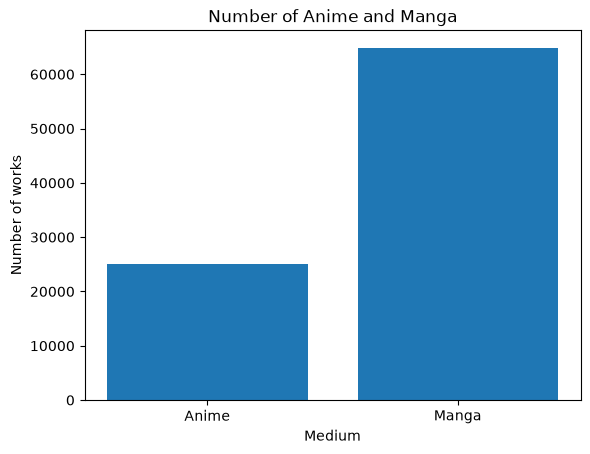

In [11]:
anime_count = len(anime_dataframe)
manga_count = len(manga_dataframe)

plt.bar(["Anime", "Manga"], [anime_count, manga_count])

plt.title("Number of Anime and Manga")
plt.xlabel("Medium")
plt.ylabel("Number of works")

plt.show()

In [12]:
anime_type_counts = anime_dataframe["type"].value_counts()
manga_type_counts = manga_dataframe["type"].value_counts()

print(anime_type_counts)
print(manga_type_counts)

type
tv         7632
movie      4389
ova        4072
ona        3523
music      2772
special    2539
Unknown      58
Name: count, dtype: int64
type
manga          44077
light_novel    10224
one_shot        5248
manhwa          2986
doujinshi       1816
manhua           350
novel            132
Name: count, dtype: int64


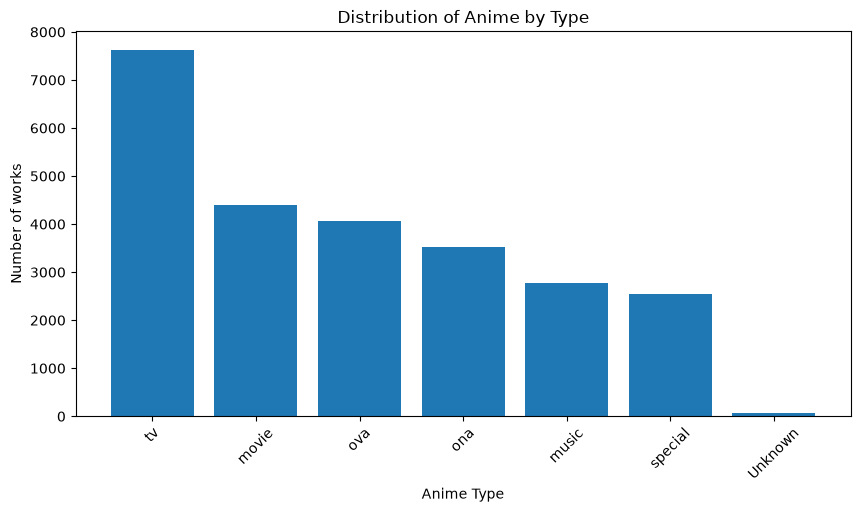

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(anime_type_counts.index, anime_type_counts.values)

plt.title("Distribution of Anime by Type")
plt.xlabel("Anime Type")
plt.ylabel("Number of works")
plt.xticks(rotation=45)

plt.show()

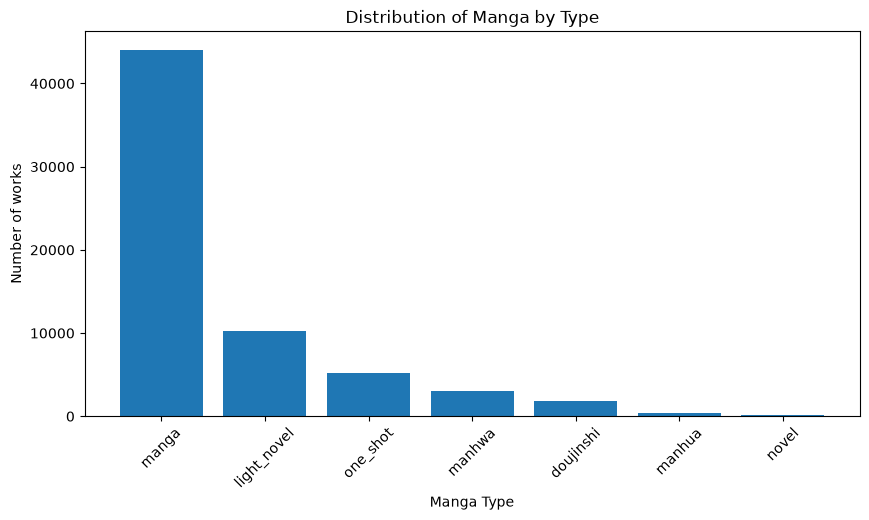

In [14]:
plt.figure(figsize=(10, 5))

plt.bar(manga_type_counts.index, manga_type_counts.values)

plt.title("Distribution of Manga by Type")
plt.xlabel("Manga Type")
plt.ylabel("Number of works")
plt.xticks(rotation=45)

plt.show()

In [15]:
print(anime_dataframe["episodes"].describe())

count    24438.000000
mean        14.877486
std         48.447625
min          1.000000
25%          1.000000
50%          2.000000
75%         13.000000
max       3057.000000
Name: episodes, dtype: float64


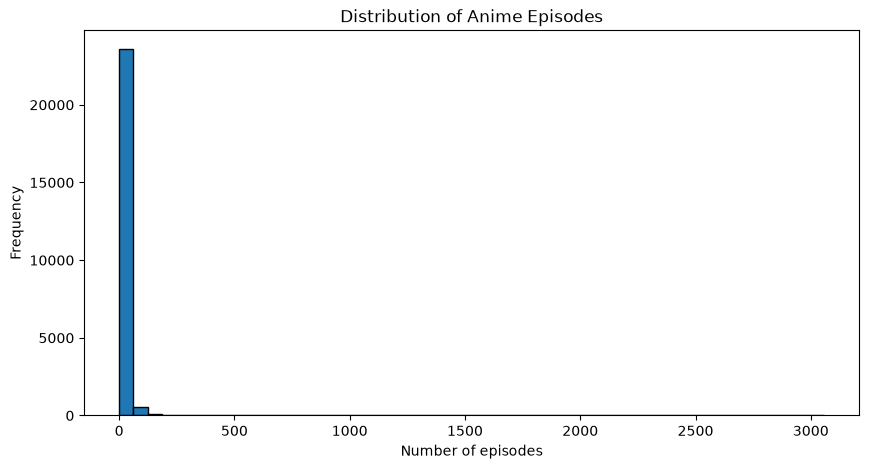

In [16]:
plt.figure(figsize=(10, 5))

plt.hist(anime_dataframe["episodes"].dropna(), bins=50, edgecolor="black")

plt.title("Distribution of Anime Episodes")
plt.xlabel("Number of episodes")
plt.ylabel("Frequency")

plt.show()

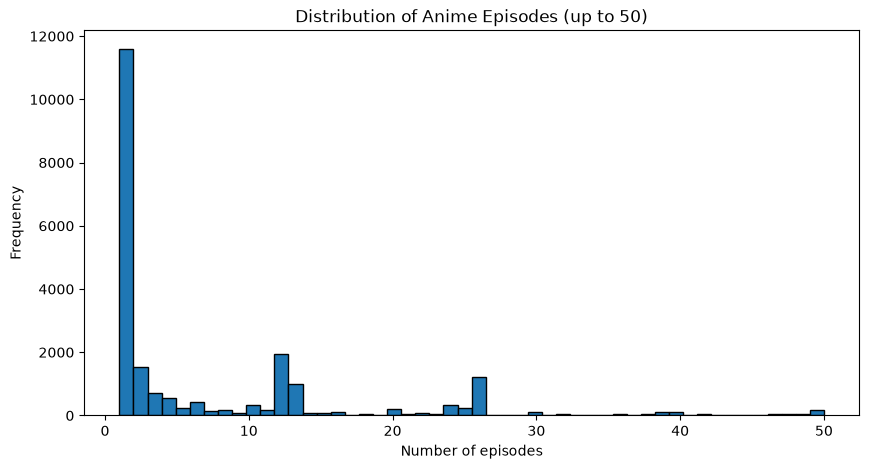

In [17]:
filtered_episodes = anime_dataframe["episodes"].dropna()
filtered_episodes = filtered_episodes[filtered_episodes <= 50]

plt.figure(figsize=(10, 5))

plt.hist(filtered_episodes, bins=50, edgecolor="black")

plt.title("Distribution of Anime Episodes (up to 50)")
plt.xlabel("Number of episodes")
plt.ylabel("Frequency")

plt.show()

In [18]:
print(manga_dataframe["chapters"].describe())
print(manga_dataframe["volumes"].describe())

count    46042.000000
mean        21.186417
std         53.896370
min          1.000000
25%          5.000000
50%          9.000000
75%         19.000000
max       6477.000000
Name: chapters, dtype: float64
count    48211.000000
mean         2.970090
std          4.771116
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        200.000000
Name: volumes, dtype: float64


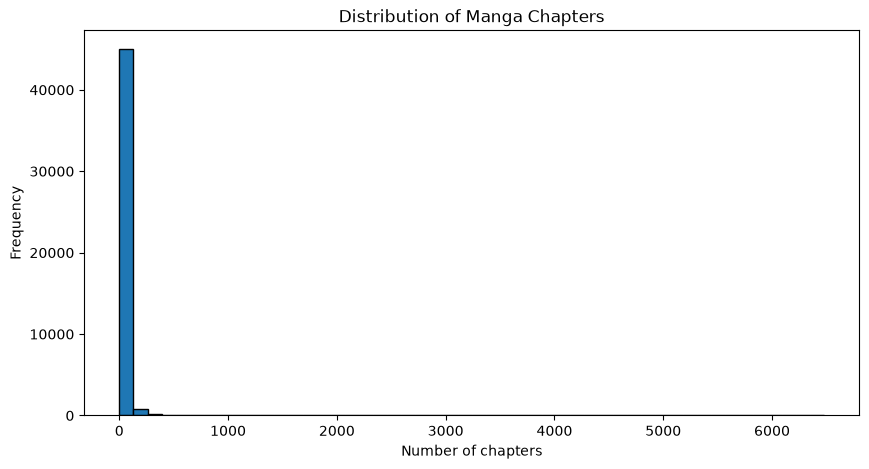

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(manga_dataframe["chapters"].dropna(), bins=50, edgecolor="black")

plt.title("Distribution of Manga Chapters")
plt.xlabel("Number of chapters")
plt.ylabel("Frequency")

plt.show()

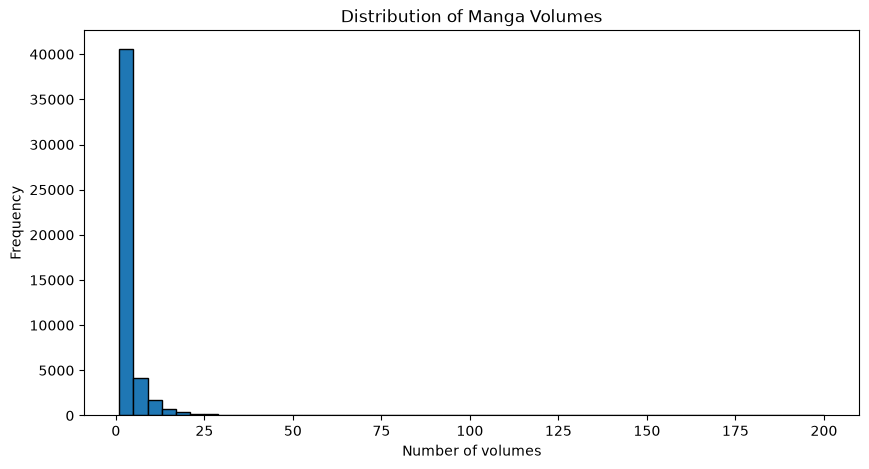

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(manga_dataframe["volumes"].dropna(), bins=50, edgecolor="black")

plt.title("Distribution of Manga Volumes")
plt.xlabel("Number of volumes")
plt.ylabel("Frequency")

plt.show()

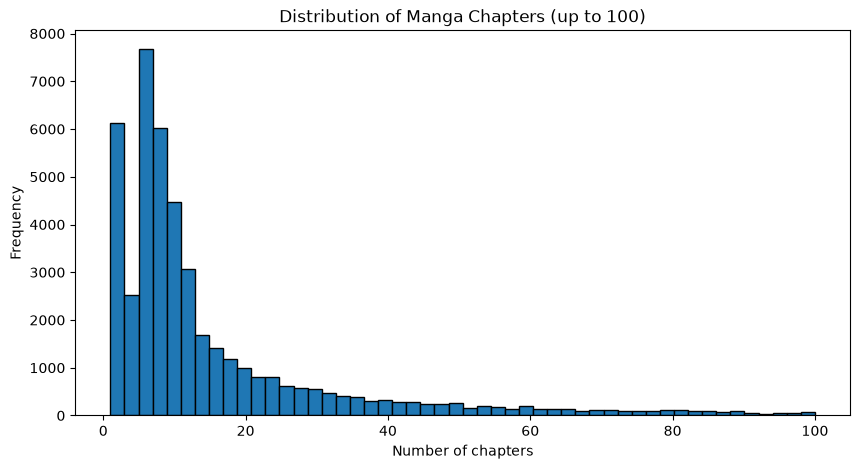

In [21]:
filtered_chapters = manga_dataframe["chapters"].dropna()
filtered_chapters = filtered_chapters[filtered_chapters <= 100]

plt.figure(figsize=(10, 5))

plt.hist(filtered_chapters, bins=50, edgecolor="black")

plt.title("Distribution of Manga Chapters (up to 100)")
plt.xlabel("Number of chapters")
plt.ylabel("Frequency")

plt.show()

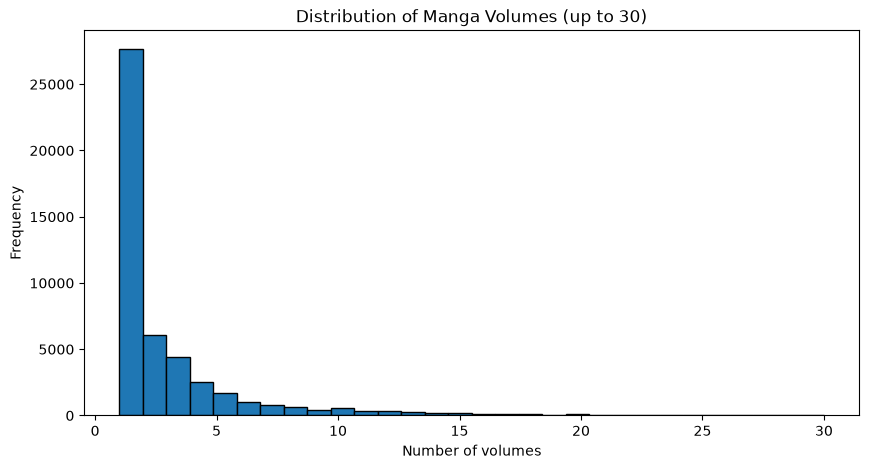

In [22]:
filtered_volumes = manga_dataframe["volumes"].dropna()
filtered_volumes = filtered_volumes[filtered_volumes <= 30]

plt.figure(figsize=(10, 5))

plt.hist(filtered_volumes, bins=30, edgecolor="black")

plt.title("Distribution of Manga Volumes (up to 30)")
plt.xlabel("Number of volumes")
plt.ylabel("Frequency")

plt.show()

In [23]:
print(anime_dataframe["members"].describe())
print(manga_dataframe["members"].describe())

count    2.498500e+04
mean     3.758410e+04
std      1.583635e+05
min      0.000000e+00
25%      2.200000e+02
50%      1.085000e+03
75%      9.499000e+03
max      3.779820e+06
Name: members, dtype: float64
count     64833.000000
mean       1758.756127
std       11083.107361
min           3.000000
25%          64.000000
50%         190.000000
75%         786.000000
max      643969.000000
Name: members, dtype: float64


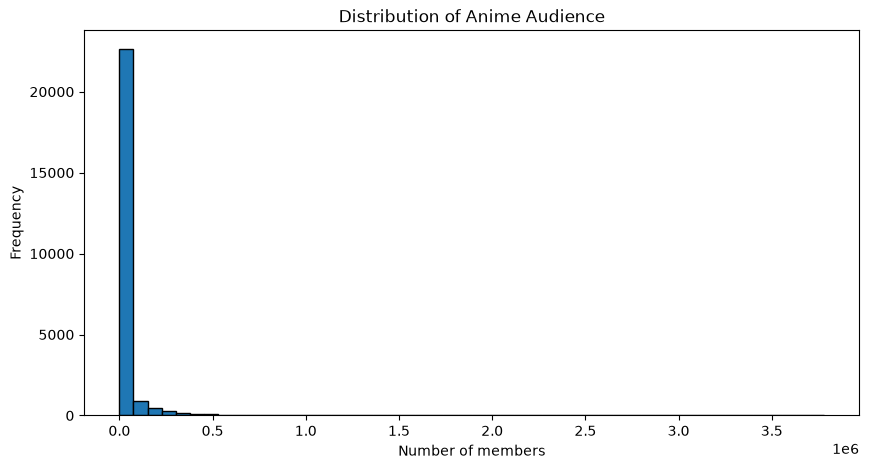

In [24]:
plt.figure(figsize=(10, 5))

plt.hist(anime_dataframe["members"].dropna(), bins=50, edgecolor="black")

plt.title("Distribution of Anime Audience")
plt.xlabel("Number of members")
plt.ylabel("Frequency")

plt.show()

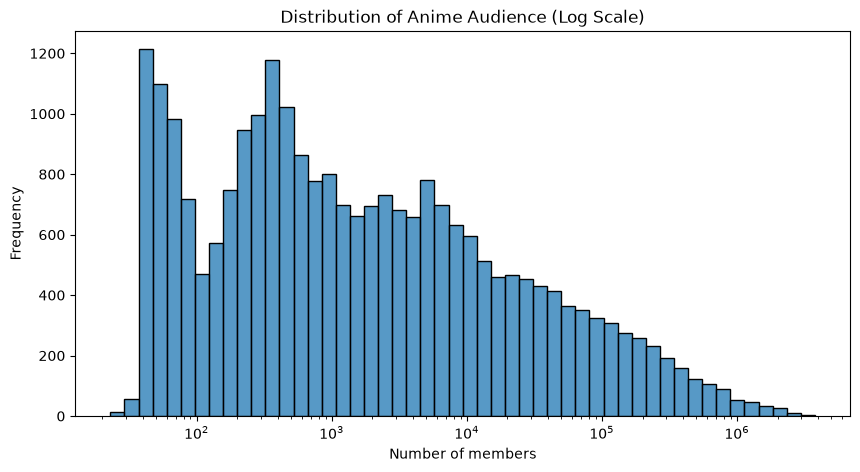

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=anime_dataframe[anime_dataframe["members"] > 0],
    x="members",
    bins=50,
    log_scale=True
)

plt.title("Distribution of Anime Audience (Log Scale)")
plt.xlabel("Number of members")
plt.ylabel("Frequency")

plt.show()

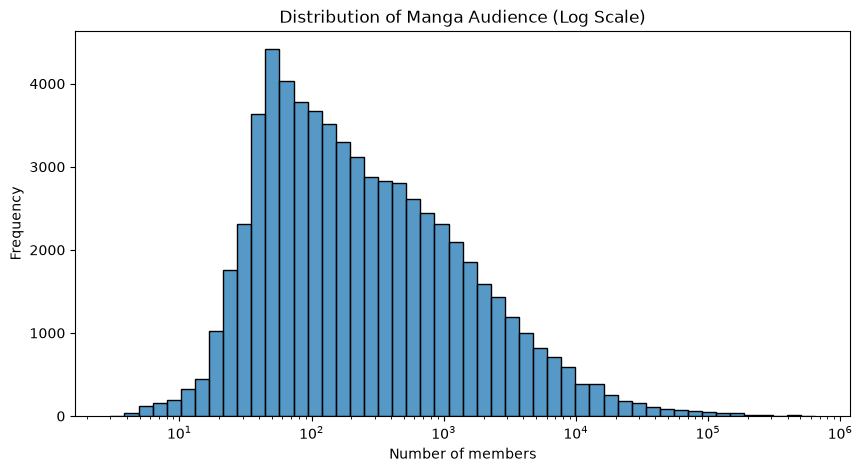

In [26]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=manga_dataframe[manga_dataframe["members"] > 0],
    x="members",
    bins=50,
    log_scale=True
)

plt.title("Distribution of Manga Audience (Log Scale)")
plt.xlabel("Number of members")
plt.ylabel("Frequency")

plt.show()

In [27]:
print(anime_dataframe["start_year"].describe())
print(manga_dataframe["start_year"].describe())

count    24110.000000
mean      2007.691580
std         14.724983
min       1917.000000
25%       2002.000000
50%       2012.000000
75%       2018.000000
max       2025.000000
Name: start_year, dtype: float64
count    62950.000000
mean      2010.681604
std          8.789400
min       1928.000000
25%       2007.000000
50%       2012.000000
75%       2017.000000
max       2023.000000
Name: start_year, dtype: float64


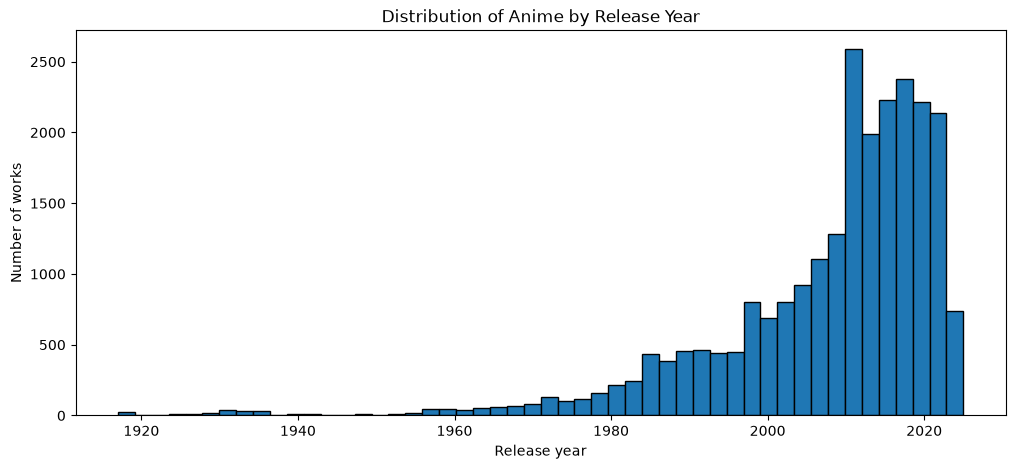

In [28]:
plt.figure(figsize=(12, 5))

plt.hist(
    anime_dataframe["start_year"].dropna(),
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Anime by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of works")

plt.show()

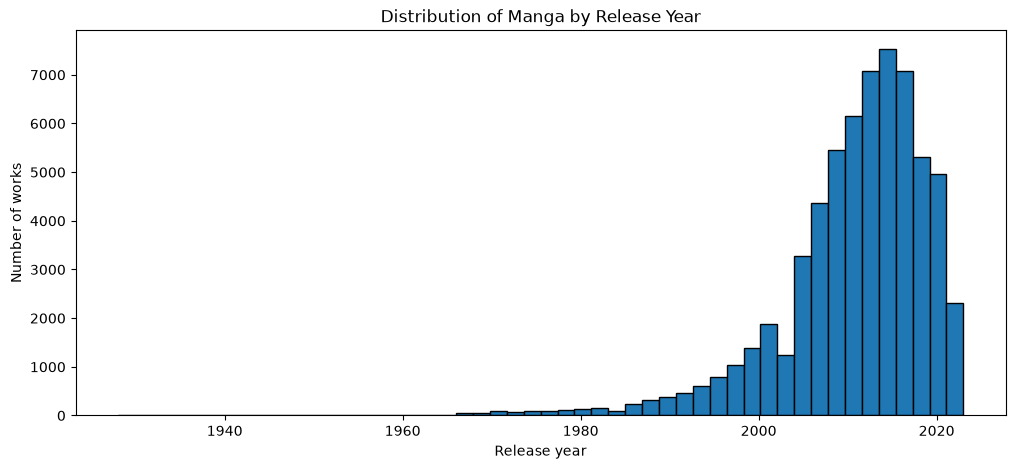

In [29]:
plt.figure(figsize=(12, 5))

plt.hist(
    manga_dataframe["start_year"].dropna(),
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Manga by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of works")

plt.show()

### Problem 3. Scores
You should already know there are many viewpoints to what we call "score". How are scores distributed and what can we learn about them?

Try to come up with a good, explainable, scoring method. There's no universal formula for this, but at the very least we should look at the number of people giving a score. A "4.5" average can mean different things if 10 or 10 000 people have voted.

In [30]:
print("Anime scores:")
print(anime_dataframe["score"].describe())

print("\nManga scores:")
print(manga_dataframe["score"].describe())

Anime scores:
count    16050.000000
mean         6.418470
std          0.899305
min          1.850000
25%          5.800000
50%          6.420000
75%          7.070000
max          9.100000
Name: score, dtype: float64

Manga scores:
count    24636.000000
mean         6.945179
std          0.520170
min          2.440000
25%          6.620000
50%          6.910000
75%          7.250000
max          9.470000
Name: score, dtype: float64


In [31]:
print("Anime missing scores:")
print(anime_dataframe["score"].isna().sum())

print("\nManga missing scores:")
print(manga_dataframe["score"].isna().sum())

Anime missing scores:
8935

Manga missing scores:
40197


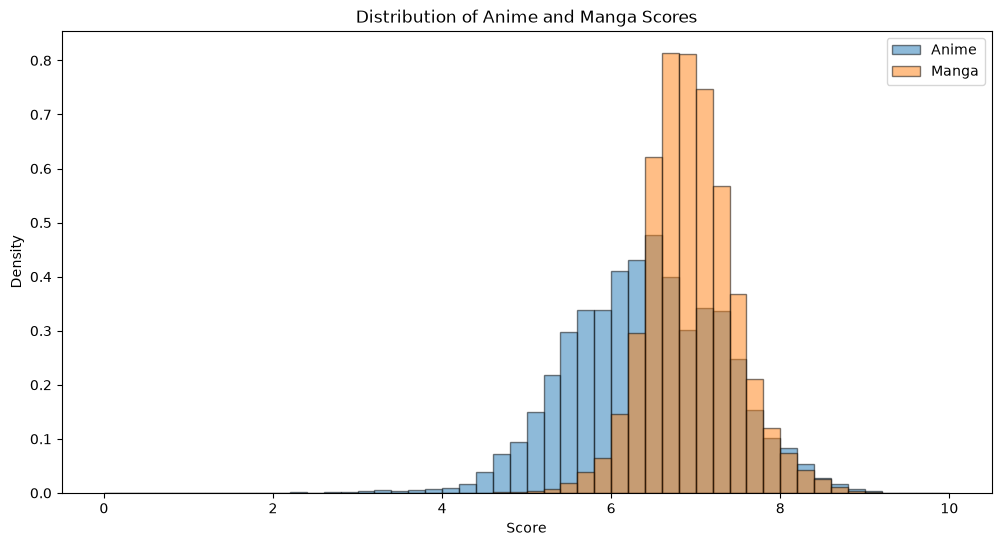

In [32]:
plt.figure(figsize=(12, 6))

plt.hist(
    anime_dataframe["score"].dropna(),
    bins=np.linspace(0, 10, 51),
    alpha=0.5,
    density=True,
    label="Anime",
    edgecolor="black"
)

plt.hist(
    manga_dataframe["score"].dropna(),
    bins=np.linspace(0, 10, 51),
    alpha=0.5,
    density=True,
    label="Manga",
    edgecolor="black"
)

plt.title("Distribution of Anime and Manga Scores")
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()

plt.show()

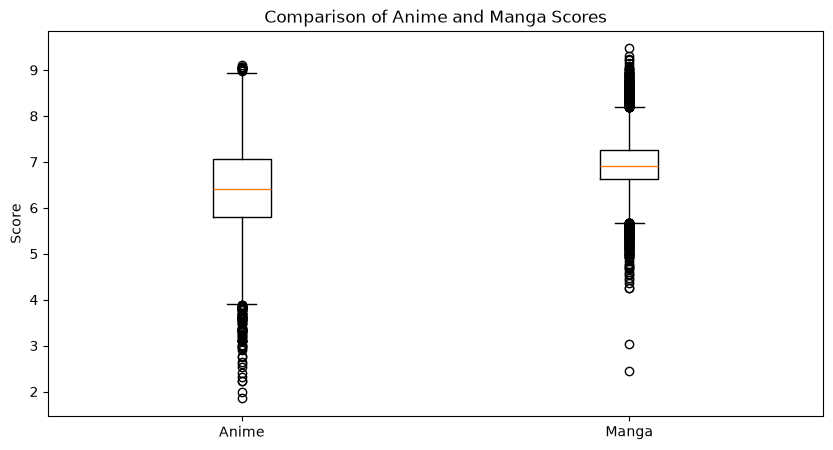

In [33]:
plt.figure(figsize=(10, 5))

plt.boxplot([
    anime_dataframe["score"].dropna(),
    manga_dataframe["score"].dropna()
], tick_labels=["Anime", "Manga"])

plt.title("Comparison of Anime and Manga Scores")
plt.ylabel("Score")
plt.show()

In [34]:
print("Anime scored by:")
print(anime_dataframe["scored_by"].describe())

print("\nManga scored by:")
print(manga_dataframe["scored_by"].describe())

Anime scored by:
count    2.498500e+04
mean     1.915352e+04
std      9.486704e+04
min      0.000000e+00
25%      5.100000e+01
50%      3.070000e+02
75%      3.433000e+03
max      2.685033e+06
Name: scored_by, dtype: float64

Manga scored by:
count     64833.000000
mean        686.997501
std        5514.493705
min           0.000000
25%           7.000000
50%          46.000000
75%         261.000000
max      394362.000000
Name: scored_by, dtype: float64


In [35]:
anime_rated = anime_dataframe[
    (anime_dataframe["score"].notna()) &
    (anime_dataframe["scored_by"] > 0)
]

manga_rated = manga_dataframe[
    (manga_dataframe["score"].notna()) &
    (manga_dataframe["scored_by"] > 0)
]

anime_m = anime_rated["scored_by"].quantile(0.75)
manga_m = manga_rated["scored_by"].quantile(0.75)

print("Anime m:", anime_m)
print("Manga m:", manga_m)

Anime m: 10595.0
Manga m: 1060.0


In [36]:
anime_C = anime_rated["score"].mean()
manga_C = manga_rated["score"].mean()

print("Anime C:", anime_C)
print("Manga C:", manga_C)

Anime C: 6.4184697819314644
Manga C: 6.9451790063321965


In [37]:
anime_dataframe["weighted_score"] = (
    anime_dataframe["scored_by"] * anime_dataframe["score"]
    + anime_m * anime_C
) / (anime_dataframe["scored_by"] + anime_m)

In [38]:
manga_dataframe["weighted_score"] = (
    manga_dataframe["scored_by"] * manga_dataframe["score"]
    + manga_m * manga_C
) / (manga_dataframe["scored_by"] + manga_m)

In [39]:
print(
    anime_dataframe.nlargest(10, "score")[
        ["display_title", "score", "scored_by", "weighted_score"]
    ]
)

print(
    anime_dataframe.nlargest(10, "weighted_score")[
        ["display_title", "score", "scored_by", "weighted_score"]
    ]
)

                                         display_title  score  scored_by  \
0                     Fullmetal Alchemist: Brotherhood   9.10    2037075   
3                                          Steins;Gate   9.07    1348232   
103                                   Gintama Season 4   9.06     240466   
114                    Bleach: Thousand-Year Blood War   9.06     228906   
2                      Attack on Titan Season 3 Part 2   9.05    1491491   
1                                      Hunter x Hunter   9.04    1671587   
38           Kaguya-sama: Love is War - Ultra Romantic   9.04     466692   
117                                   Gintama Season 2   9.04     228236   
187  Attack on Titan: The Final Season - Final Chap...   9.04     170844   
477                            Gintama: The Very Final   9.04      65116   

     weighted_score  
0          9.086125  
3          9.049326  
103        8.948525  
114        8.943144  
2          9.031438  
1          9.023489  
38       

In [40]:
print(
    manga_dataframe.nlargest(10, "score")[
        ["display_title", "score", "scored_by", "weighted_score"]
    ]
)

                                      display_title  score  scored_by  \
0                                           Berserk   9.47     319696   
2   JoJo no Kimyou na Bouken Part 7: Steel Ball Run   9.30     151433   
5                                          Vagabond   9.24     129688   
1                                         One Piece   9.22     355375   
9                                           Monster   9.15      90296   
16                                        Slam Dunk   9.08      70877   
6                                      Vinland Saga   9.05     119797   
4                               Fullmetal Alchemist   9.03     153151   
18                              Grand Blue Dreaming   9.03      63438   
3                                  Goodnight Punpun   9.02     168459   

    weighted_score  
0         9.461656  
2         9.283631  
5         9.221395  
1         9.213235  
9         9.124418  
16        9.048543  
6         9.031539  
4         9.015670  
18     

In [41]:
print(
    manga_dataframe.nlargest(10, "weighted_score")[
        ["display_title", "score", "scored_by", "weighted_score"]
    ]
)

                                      display_title  score  scored_by  \
0                                           Berserk   9.47     319696   
2   JoJo no Kimyou na Bouken Part 7: Steel Ball Run   9.30     151433   
5                                          Vagabond   9.24     129688   
1                                         One Piece   9.22     355375   
9                                           Monster   9.15      90296   
16                                        Slam Dunk   9.08      70877   
6                                      Vinland Saga   9.05     119797   
4                               Fullmetal Alchemist   9.03     153151   
3                                  Goodnight Punpun   9.02     168459   
18                              Grand Blue Dreaming   9.03      63438   

    weighted_score  
0         9.461656  
2         9.283631  
5         9.221395  
1         9.213235  
9         9.124418  
16        9.048543  
6         9.031539  
4         9.015670  
3      

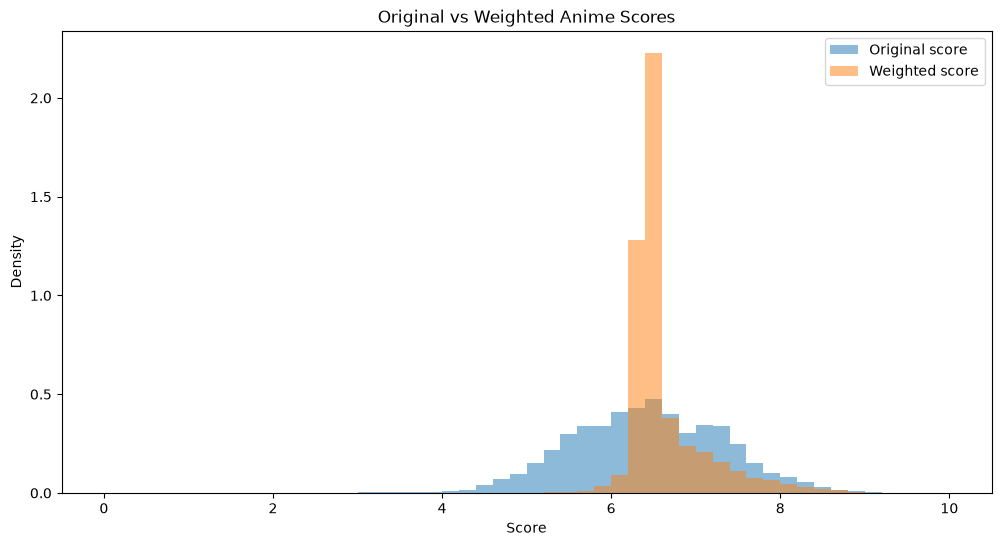

In [42]:
plt.figure(figsize=(12, 6))

plt.hist(
    anime_dataframe["score"].dropna(),
    bins=np.linspace(0, 10, 51),
    alpha=0.5,
    density=True,
    label="Original score"
)

plt.hist(
    anime_dataframe["weighted_score"].dropna(),
    bins=np.linspace(0, 10, 51),
    alpha=0.5,
    density=True,
    label="Weighted score"
)

plt.title("Original vs Weighted Anime Scores")
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()

plt.show()

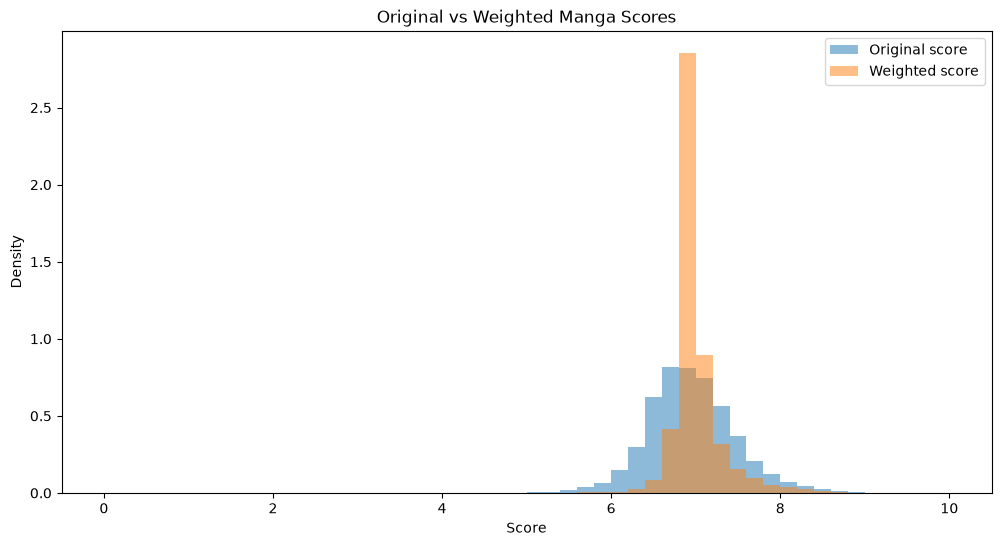

In [43]:
plt.figure(figsize=(12, 6))

plt.hist(
    manga_dataframe["score"].dropna(),
    bins=np.linspace(0, 10, 51),
    alpha=0.5,
    density=True,
    label="Original score"
)

plt.hist(
    manga_dataframe["weighted_score"].dropna(),
    bins=np.linspace(0, 10, 51),
    alpha=0.5,
    density=True,
    label="Weighted score"
)

plt.title("Original vs Weighted Manga Scores")
plt.xlabel("Score")
plt.ylabel("Density")
plt.legend()

plt.show()

In [44]:
print("Anime:")
print(anime_dataframe[["score", "weighted_score"]].std())

print("\nManga:")
print(manga_dataframe[["score", "weighted_score"]].std())

Anime:
score             0.899305
weighted_score    0.446150
dtype: float64

Manga:
score             0.520170
weighted_score    0.291229
dtype: float64


### Problem 4. Score and popularity
Try to view the "score" through the lens of the other popularity features. For example, number of times it's been added to favorites. How similar (or different) are score and popularity? Can you figure out any groups (clusters)?

In [46]:
popularity_columns = ["score", "members", "scored_by", "favorites"]

print("Anime:")
print(anime_dataframe[popularity_columns].describe())

print("\nManga:")
print(manga_dataframe[popularity_columns].describe())

Anime:
              score       members     scored_by      favorites
count  16050.000000  2.498500e+04  2.498500e+04   24985.000000
mean       6.418470  3.758410e+04  1.915352e+04     437.147328
std        0.899305  1.583635e+05  9.486704e+04    4390.169453
min        1.850000  0.000000e+00  0.000000e+00       0.000000
25%        5.800000  2.200000e+02  5.100000e+01       0.000000
50%        6.420000  1.085000e+03  3.070000e+02       1.000000
75%        7.070000  9.499000e+03  3.433000e+03      18.000000
max        9.100000  3.779820e+06  2.685033e+06  219036.000000

Manga:
              score        members      scored_by      favorites
count  24636.000000   64833.000000   64833.000000   64833.000000
mean       6.945179    1758.756127     686.997501      54.991440
std        0.520170   11083.107361    5514.493705    1057.059487
min        2.440000       3.000000       0.000000       0.000000
25%        6.620000      64.000000       7.000000       0.000000
50%        6.910000     190.

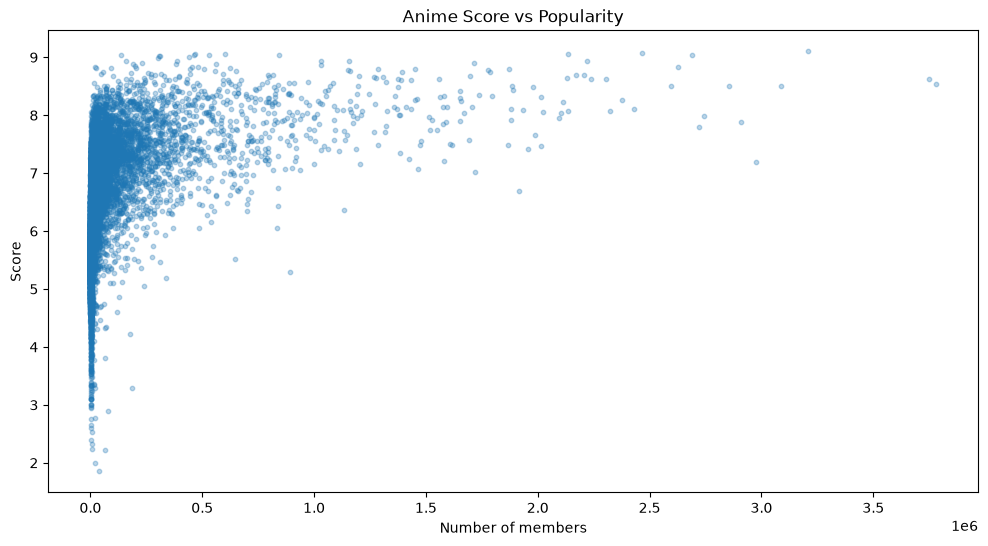

In [47]:
plt.figure(figsize=(12, 6))

plt.scatter(
    anime_dataframe["members"],
    anime_dataframe["score"],
    alpha=0.3,
    s=10
)

plt.title("Anime Score vs Popularity")
plt.xlabel("Number of members")
plt.ylabel("Score")

plt.show()

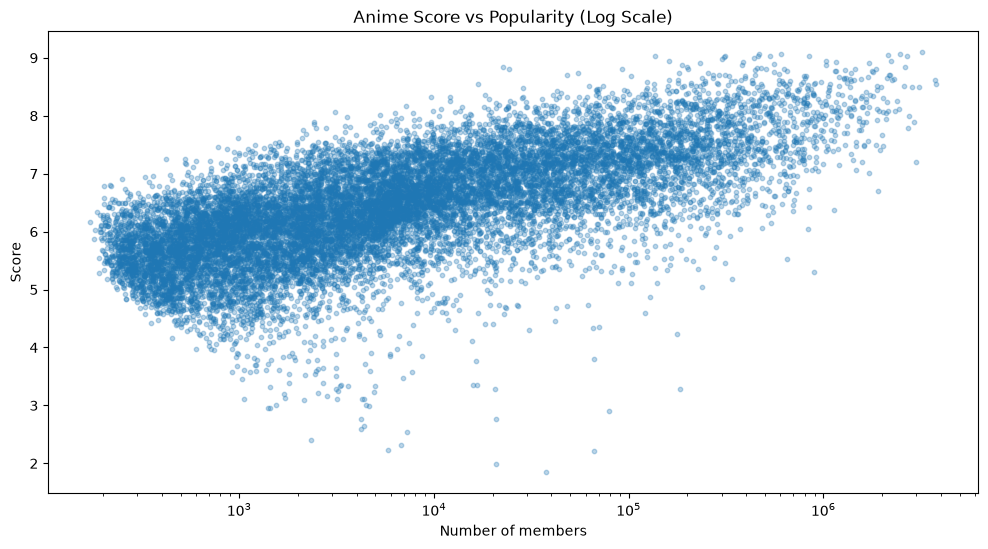

In [48]:
anime_popularity = anime_dataframe[
    (anime_dataframe["members"] > 0) &
    (anime_dataframe["score"].notna())
]

plt.figure(figsize=(12, 6))

plt.scatter(
    anime_popularity["members"],
    anime_popularity["score"],
    alpha=0.3,
    s=10
)

plt.xscale("log")

plt.title("Anime Score vs Popularity (Log Scale)")
plt.xlabel("Number of members")
plt.ylabel("Score")

plt.show()

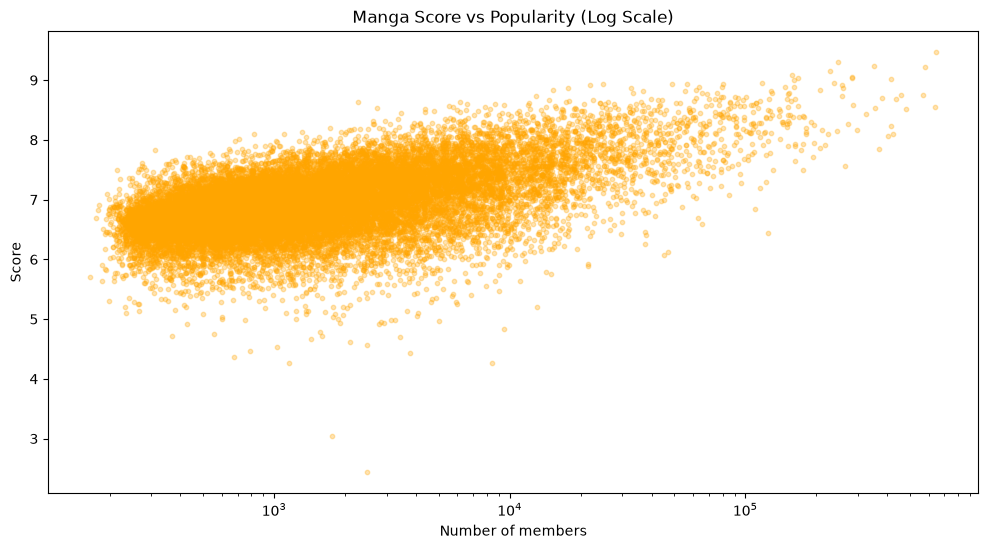

In [49]:
manga_popularity = manga_dataframe[
    (manga_dataframe["members"] > 0) &
    (manga_dataframe["score"].notna())
]

plt.figure(figsize=(12, 6))

plt.scatter(
    manga_popularity["members"],
    manga_popularity["score"],
    alpha=0.3,
    s=10,
    color="orange"
)

plt.xscale("log")

plt.title("Manga Score vs Popularity (Log Scale)")
plt.xlabel("Number of members")
plt.ylabel("Score")

plt.show()

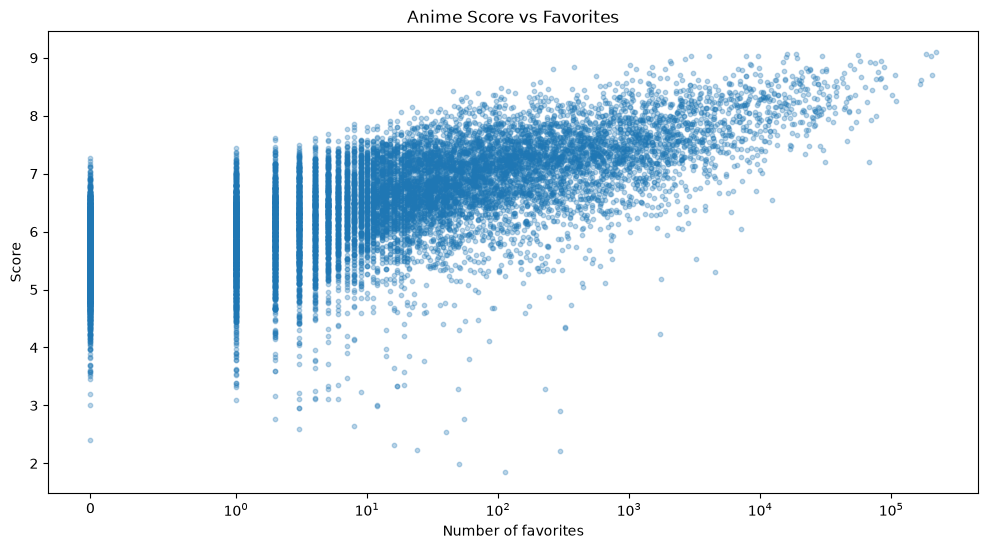

In [50]:
plt.figure(figsize=(12, 6))

plt.scatter(
    anime_dataframe["favorites"],
    anime_dataframe["score"],
    alpha=0.3,
    s=10
)

plt.xscale("symlog", linthresh=1)

plt.title("Anime Score vs Favorites")
plt.xlabel("Number of favorites")
plt.ylabel("Score")

plt.show()

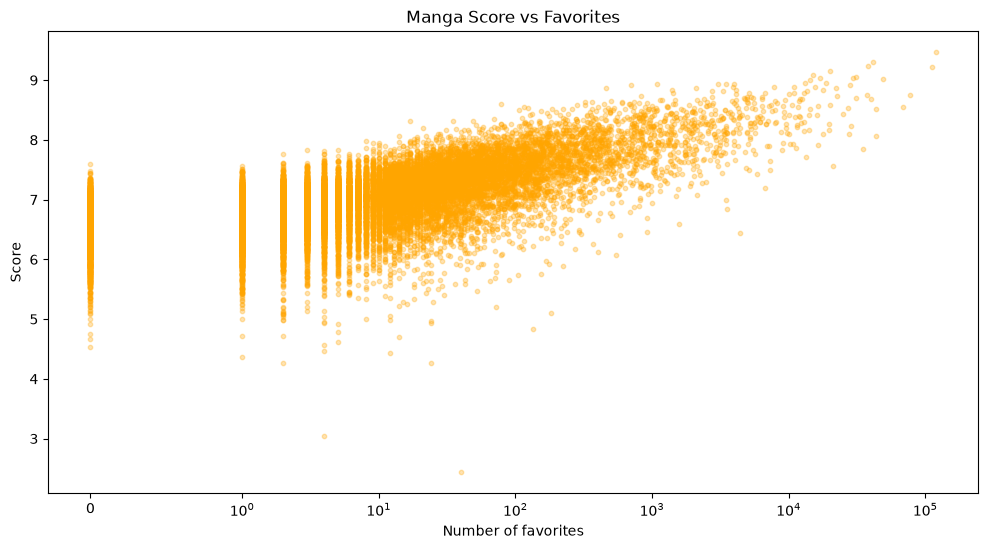

In [51]:
plt.figure(figsize=(12, 6))

plt.scatter(
    manga_dataframe["favorites"],
    manga_dataframe["score"],
    alpha=0.3,
    s=10,
    color="orange"
)

plt.xscale("symlog", linthresh=1)

plt.title("Manga Score vs Favorites")
plt.xlabel("Number of favorites")
plt.ylabel("Score")

plt.show()

In [52]:
popularity_columns = ["score", "members", "scored_by", "favorites"]

anime_correlation = anime_dataframe[popularity_columns].corr()
manga_correlation = manga_dataframe[popularity_columns].corr()

print("Anime correlation:")
print(anime_correlation.round(3))

print("\nManga correlation:")
print(manga_correlation.round(3))

Anime correlation:
           score  members  scored_by  favorites
score      1.000    0.389      0.350      0.236
members    0.389    1.000      0.989      0.773
scored_by  0.350    0.989      1.000      0.785
favorites  0.236    0.773      0.785      1.000

Manga correlation:
           score  members  scored_by  favorites
score      1.000    0.341      0.284      0.215
members    0.341    1.000      0.977      0.873
scored_by  0.284    0.977      1.000      0.901
favorites  0.215    0.873      0.901      1.000


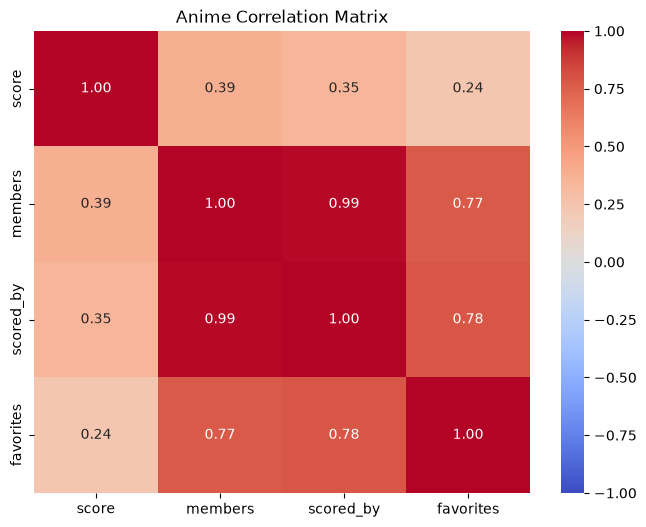

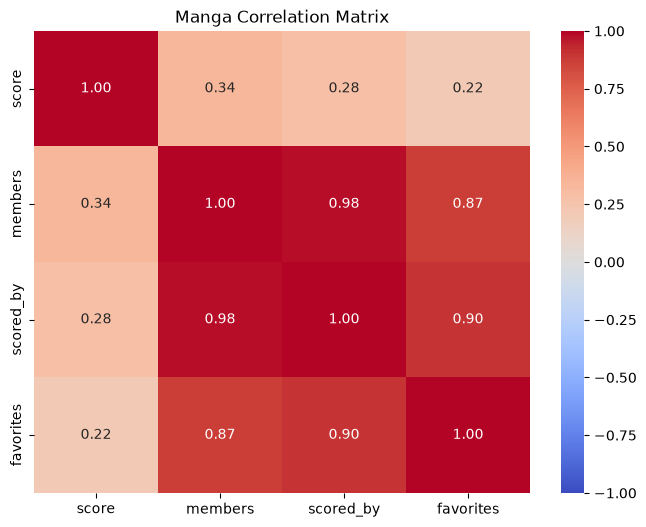

In [55]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    anime_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Anime Correlation Matrix")
plt.show()


plt.figure(figsize=(8, 6))

sns.heatmap(
    manga_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Manga Correlation Matrix")
plt.show()

In [56]:
anime_log = anime_dataframe[popularity_columns].copy()
manga_log = manga_dataframe[popularity_columns].copy()

log_columns = ["members", "scored_by", "favorites"]

anime_log[log_columns] = np.log1p(anime_log[log_columns])
manga_log[log_columns] = np.log1p(manga_log[log_columns])

print("Anime:")
print(anime_log.corr().round(3))

print("\nManga:")
print(manga_log.corr().round(3))

Anime:
           score  members  scored_by  favorites
score      1.000    0.685      0.670      0.717
members    0.685    1.000      0.936      0.908
scored_by  0.670    0.936      1.000      0.839
favorites  0.717    0.908      0.839      1.000

Manga:
           score  members  scored_by  favorites
score      1.000    0.557      0.498      0.682
members    0.557    1.000      0.963      0.821
scored_by  0.498    0.963      1.000      0.758
favorites  0.682    0.821      0.758      1.000


In [57]:
anime_hidden_gems = anime_dataframe[
    (anime_dataframe["score"] >= 8) &
    (anime_dataframe["members"] < 1000)
]

print(
    anime_hidden_gems[
        ["display_title", "score", "members", "scored_by"]
    ].sort_values("score", ascending=False)
)

Empty DataFrame
Columns: [display_title, score, members, scored_by]
Index: []


In [58]:
score_threshold = anime_popularity["score"].quantile(0.75)
members_threshold = anime_popularity["members"].median()

anime_hidden_gems = anime_popularity[
    (anime_popularity["score"] >= score_threshold) &
    (anime_popularity["members"] < members_threshold)
]

print("Score threshold:", score_threshold)
print("Members threshold:", members_threshold)
print("Hidden gems:", len(anime_hidden_gems))

print(
    anime_hidden_gems[
        ["display_title", "score", "members"]
    ].sort_values("score", ascending=False).head(10)
)

Score threshold: 7.07
Members threshold: 4796.0
Hidden gems: 336
                                          display_title  score  members
3701                                         Tot Musica   8.06     3108
4564  Touhou Fantasy Kaleidoscope: The Memories of P...   7.98     3581
5030                          Throne of Seal 2nd Season   7.90     2420
4272                                        New Genesis   7.86     2405
4488                                     Swallowed Star   7.84     4708
3791  I'm Your Treasure Box: Anata wa Marine Senchou...   7.83     3502
4376  Star☆Twinkle Precure: Hoshi no Uta ni Omoi wo ...   7.81     3720
4271                                      Ghost (Music)   7.79     2485
4114                                         Fight Song   7.79     2781
4571                                          Backlight   7.75     2127


In [59]:
manga_score_threshold = manga_popularity["score"].quantile(0.75)
manga_members_threshold = manga_popularity["members"].median()

manga_hidden_gems = manga_popularity[
    (manga_popularity["score"] >= manga_score_threshold) &
    (manga_popularity["members"] < manga_members_threshold)
]

print("Score threshold:", manga_score_threshold)
print("Members threshold:", manga_members_threshold)
print("Hidden gems:", len(manga_hidden_gems))

print(
    manga_hidden_gems[
        ["display_title", "score", "members"]
    ].sort_values("score", ascending=False).head(10)
)

Score threshold: 7.25
Members threshold: 1191.0
Hidden gems: 952
                                          display_title  score  members
6735                                 Shinai naru Gene e   8.10      818
3961                                Kocchi Muite! Miiko   8.10     1106
6154                                       Buttobi Itto   8.02      710
9800                        Lonely Castle in the Mirror   7.98      681
5176                                       Kattobi Itto   7.98     1018
5844                                             Shoot!   7.96     1024
5320                                      Love Nest 2nd   7.92      960
6356  Higurashi no Naku Koro ni Kai - Dai 1-wa: Meak...   7.90     1062
5501                                   Mega Man Gigamix   7.90     1049
8681                                Banner of the Stars   7.89      917


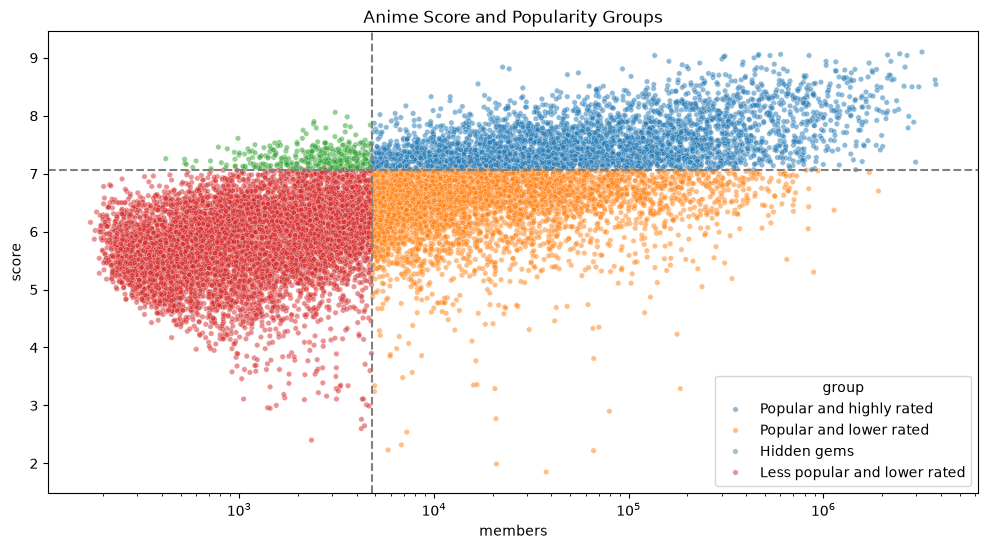

In [60]:
anime_groups = anime_popularity.copy()

anime_groups["group"] = np.select(
    [
        (anime_groups["score"] >= score_threshold) &
        (anime_groups["members"] >= members_threshold),

        (anime_groups["score"] >= score_threshold) &
        (anime_groups["members"] < members_threshold),

        (anime_groups["score"] < score_threshold) &
        (anime_groups["members"] >= members_threshold)
    ],
    [
        "Popular and highly rated",
        "Hidden gems",
        "Popular and lower rated"
    ],
    default="Less popular and lower rated"
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=anime_groups,
    x="members",
    y="score",
    hue="group",
    alpha=0.5,
    s=15
)

plt.xscale("log")
plt.axhline(score_threshold, linestyle="--", color="gray")
plt.axvline(members_threshold, linestyle="--", color="gray")

plt.title("Anime Score and Popularity Groups")
plt.show()

In [65]:
manga_groups = manga_popularity.copy()

manga_groups["group"] = np.select(
    [
        (manga_groups["score"] >= manga_score_threshold) &
        (manga_groups["members"] >= manga_members_threshold),

        (manga_groups["score"] >= manga_score_threshold) &
        (manga_groups["members"] < manga_members_threshold),

        (manga_groups["score"] < manga_score_threshold) &
        (manga_groups["members"] >= manga_members_threshold)
    ],
    [
        "Popular and highly rated",
        "Hidden gems",
        "Popular and lower rated"
    ],
    default="Less popular and lower rated"
)


- Score and popularity are positively correlated.
- Logarithmic transformation reveals stronger correlations.
- Favorites have the strongest correlation with score
  after logarithmic transformation.
- We identified 336 Anime and 952 Manga hidden gems.
- Four groups were defined using statistical thresholds,
  rather than automatic clustering.

### Problem 5. Compare anime and manga visually
You can use the merged dataset, or keep them separate. Select features that you can meaningfully compare across the two mediums and try to draw conclusions. Do they behave similarly? How? If possible, try to explain why; you'll likely need additional "domain" knowledge for this.

In [66]:
print(unified_dataframe.columns.tolist())
print(unified_dataframe["medium"].value_counts())

['work_id', 'medium', 'title', 'normalized_title', 'display_title', 'type', 'score', 'scored_by', 'members', 'favorites', 'status', 'start_year', 'genres', 'themes', 'demographics']
medium
Manga    64833
Anime    24985
Name: count, dtype: int64


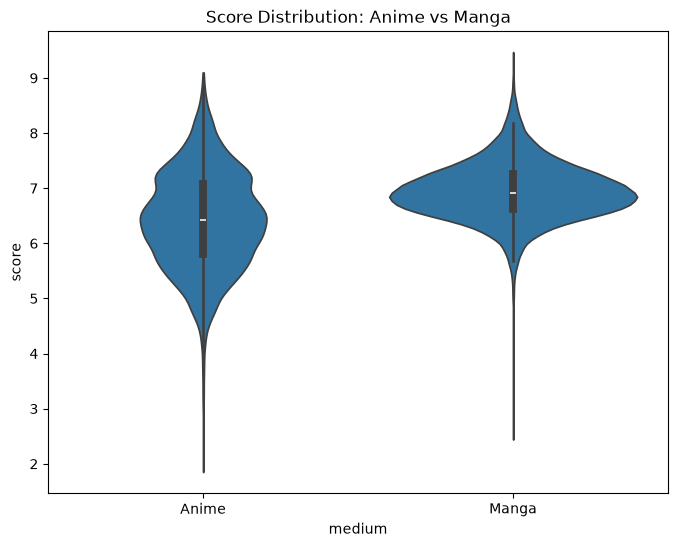

In [67]:
plt.figure(figsize=(8, 6))

sns.violinplot(
    data=unified_dataframe,
    x="medium",
    y="score",
    inner="box",
    cut=0
)

plt.title("Score Distribution: Anime vs Manga")
plt.show()

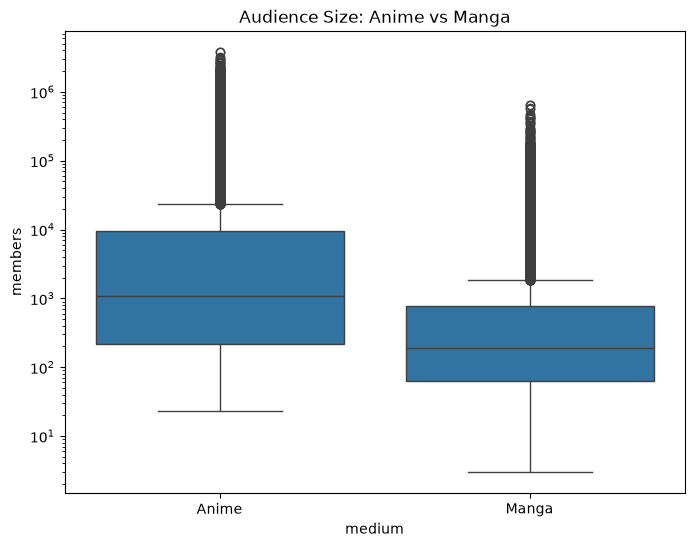

In [68]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=unified_dataframe[unified_dataframe["members"] > 0],
    x="medium",
    y="members"
)

plt.yscale("log")
plt.title("Audience Size: Anime vs Manga")
plt.show()

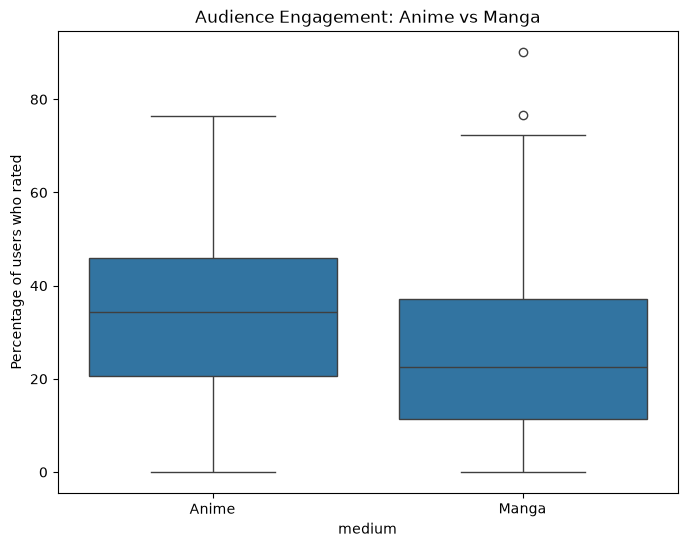

In [69]:
engagement_dataframe = unified_dataframe[
    (unified_dataframe["members"] > 0) &
    (unified_dataframe["scored_by"].notna())
].copy()

engagement_dataframe["rating_percentage"] = (
    engagement_dataframe["scored_by"] /
    engagement_dataframe["members"]
) * 100

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=engagement_dataframe,
    x="medium",
    y="rating_percentage"
)

plt.ylabel("Percentage of users who rated")
plt.title("Audience Engagement: Anime vs Manga")
plt.show()

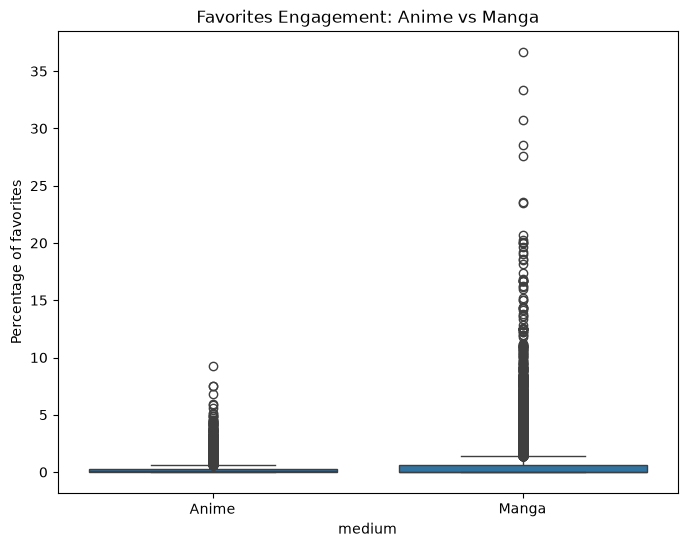

In [70]:
engagement_dataframe["favorites_percentage"] = (
    engagement_dataframe["favorites"] /
    engagement_dataframe["members"]
) * 100

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=engagement_dataframe,
    x="medium",
    y="favorites_percentage"
)

plt.ylabel("Percentage of favorites")
plt.title("Favorites Engagement: Anime vs Manga")
plt.show()


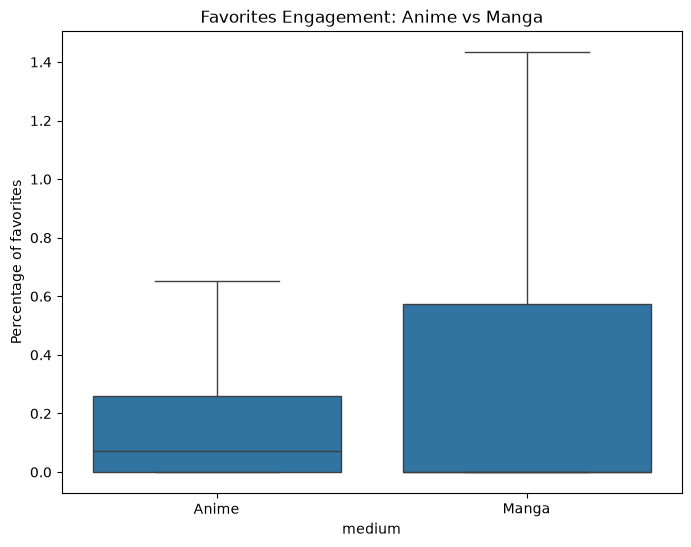

In [71]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=engagement_dataframe,
    x="medium",
    y="favorites_percentage",
    showfliers=False
)

plt.ylabel("Percentage of favorites")
plt.title("Favorites Engagement: Anime vs Manga")
plt.show()

In [72]:
comparison_columns = [
    "score",
    "members",
    "scored_by",
    "favorites",
    "rating_percentage",
    "favorites_percentage"
]

print(
    engagement_dataframe.groupby("medium")[comparison_columns]
    .median()
    .round(2)
    .T
)

medium                  Anime   Manga
score                    6.42    6.91
members               1085.00  190.00
scored_by              307.00   46.00
favorites                1.00    0.00
rating_percentage       34.43   22.65
favorites_percentage     0.07    0.00


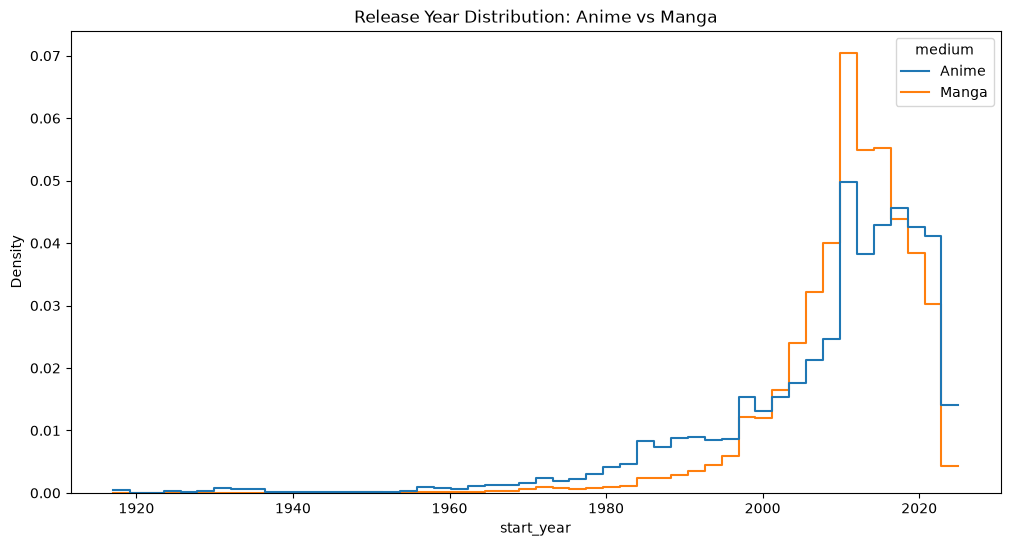

In [73]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=unified_dataframe,
    x="start_year",
    hue="medium",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Release Year Distribution: Anime vs Manga")
plt.show()

- Manga has higher and more concentrated scores.
- Anime has a larger audience and a higher rating participation rate.
- Both mediums show highly skewed popularity distributions.
- Adding works to favorites is relatively rare in both mediums.
- Both mediums show substantial growth in recorded titles after 2000.
- Streaming accessibility and audience preferences may explain
  some differences, but further research is needed.

### * Problem 6. Time series
There are a ton of works in the dataset. Most tendencies, when averaged out, will be blurred.

A special type of analysis we can do is _time series_. If you look at the dataset as a function of time, can you find some tendencies across decades, or years, or even seasons? Try to think about volume (counts and frequencies), ratings (are newer works considered better?), genres, etc.

How does the analysis of scores from Problem 3 correspond to "recency", i.e., are recent works (animes / mangas) liked better; or are classics better? Keep in mind that older works have had _more time_ to be evaluated. Come up with one (or more...) definition of "better" and defend it. Pay special attention to the number of voters.

In [75]:
time_dataframe = unified_dataframe.dropna(
    subset=["start_year"]
).copy()

time_dataframe["start_year"] = time_dataframe["start_year"].astype(int)

time_dataframe["decade"] = (
    time_dataframe["start_year"] // 10
) * 10

print(
    time_dataframe[["display_title", "medium", "start_year", "decade"]]
    .head(10)
)

                             display_title medium  start_year  decade
0         Fullmetal Alchemist: Brotherhood  Anime        2009    2000
1                          Hunter x Hunter  Anime        2011    2010
2          Attack on Titan Season 3 Part 2  Anime        2019    2010
3                              Steins;Gate  Anime        2011    2010
4                           A Silent Voice  Anime        2016    2010
5                               Your Name.  Anime        2016    2010
6  Code Geass: Lelouch of the Rebellion R2  Anime        2008    2000
7            Attack on Titan: Final Season  Anime        2020    2020
8                            Spirited Away  Anime        2001    2000
9     Code Geass: Lelouch of the Rebellion  Anime        2006    2000


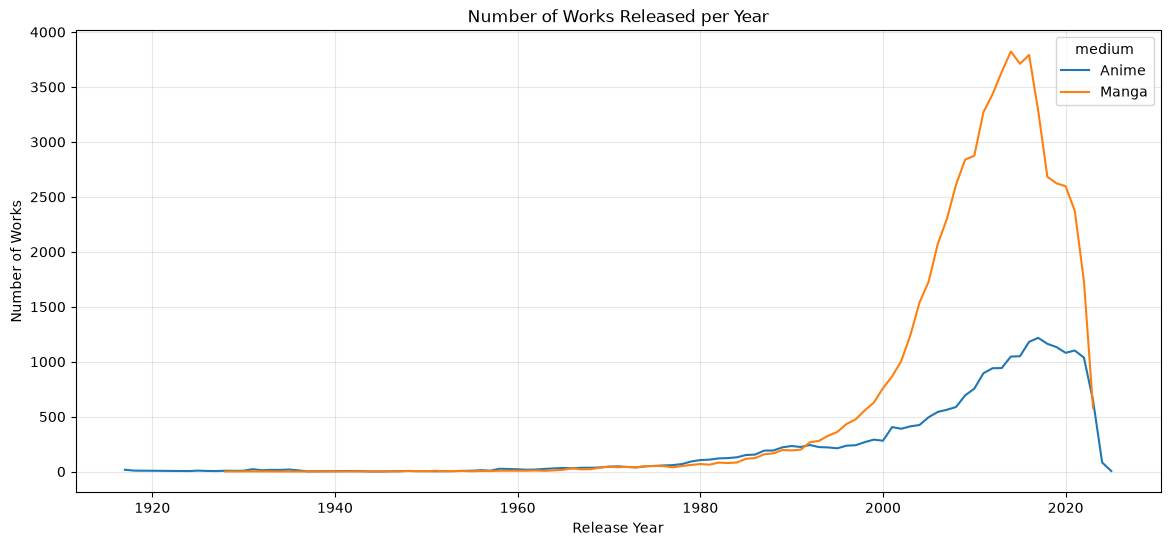

In [76]:
yearly_counts = (
    time_dataframe.groupby(["start_year", "medium"])
    .size()
    .reset_index(name="count")
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_counts,
    x="start_year",
    y="count",
    hue="medium"
)

plt.title("Number of Works Released per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Works")
plt.grid(alpha=0.3)
plt.show()


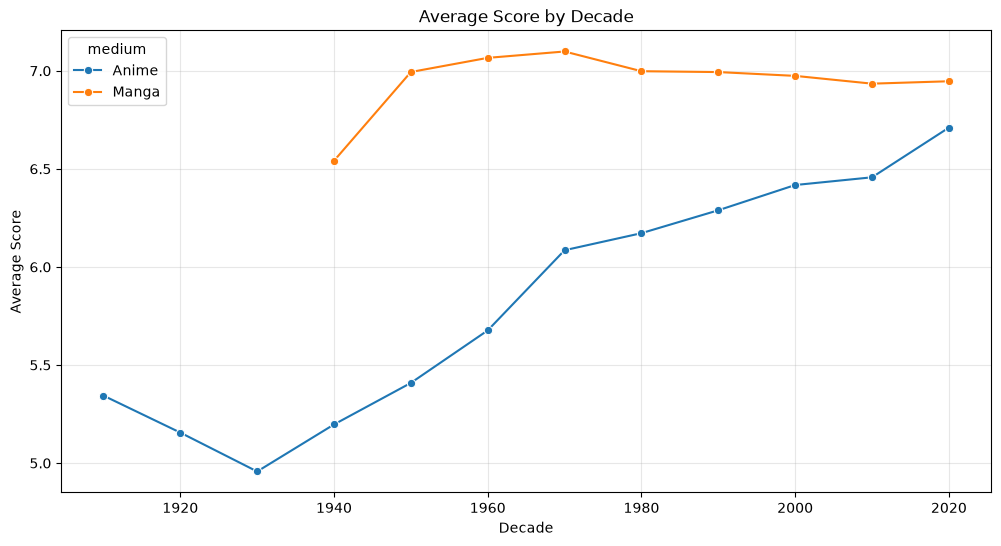

In [77]:
decade_scores = (
    time_dataframe.groupby(["decade", "medium"])["score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=decade_scores,
    x="decade",
    y="score",
    hue="medium",
    marker="o"
)

plt.title("Average Score by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Score")
plt.grid(alpha=0.3)
plt.show()

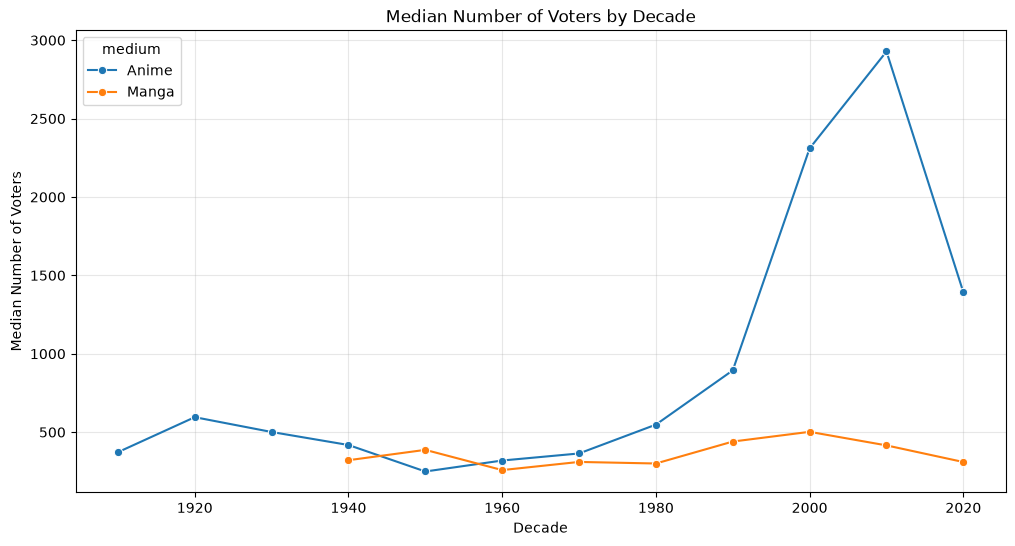

In [78]:
decade_voters = (
    time_dataframe[time_dataframe["score"].notna()]
    .groupby(["decade", "medium"])["scored_by"]
    .median()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=decade_voters,
    x="decade",
    y="scored_by",
    hue="medium",
    marker="o"
)

plt.title("Median Number of Voters by Decade")
plt.xlabel("Decade")
plt.ylabel("Median Number of Voters")
plt.grid(alpha=0.3)
plt.show()

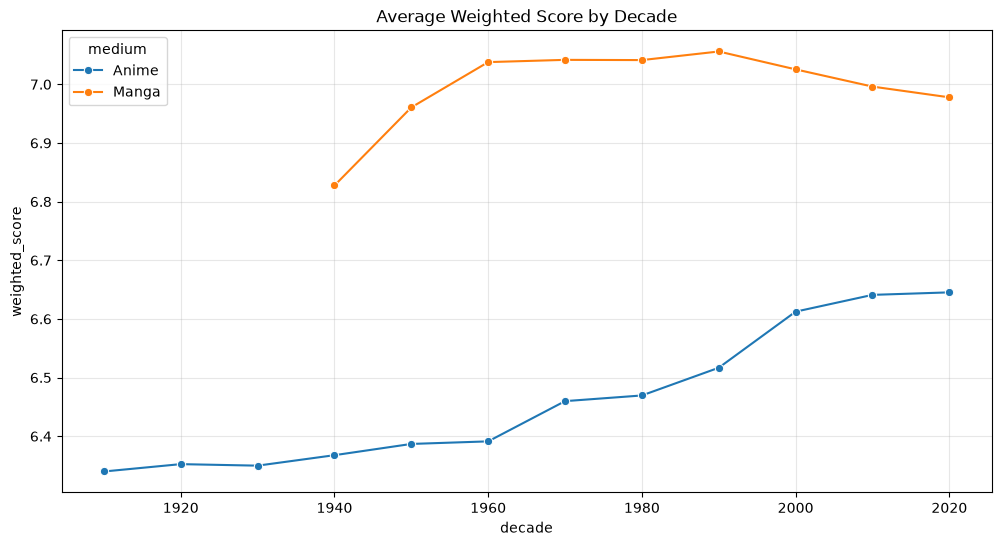

In [79]:
weighted_scores = pd.concat([
    anime_dataframe[["start_year", "weighted_score"]].assign(medium="Anime"),
    manga_dataframe[["start_year", "weighted_score"]].assign(medium="Manga")
])

weighted_scores = weighted_scores.dropna(
    subset=["start_year", "weighted_score"]
)

weighted_scores["decade"] = (
    weighted_scores["start_year"].astype(int) // 10
) * 10

decade_weighted_scores = (
    weighted_scores.groupby(["decade", "medium"])["weighted_score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=decade_weighted_scores,
    x="decade",
    y="weighted_score",
    hue="medium",
    marker="o"
)

plt.title("Average Weighted Score by Decade")
plt.grid(alpha=0.3)
plt.show()

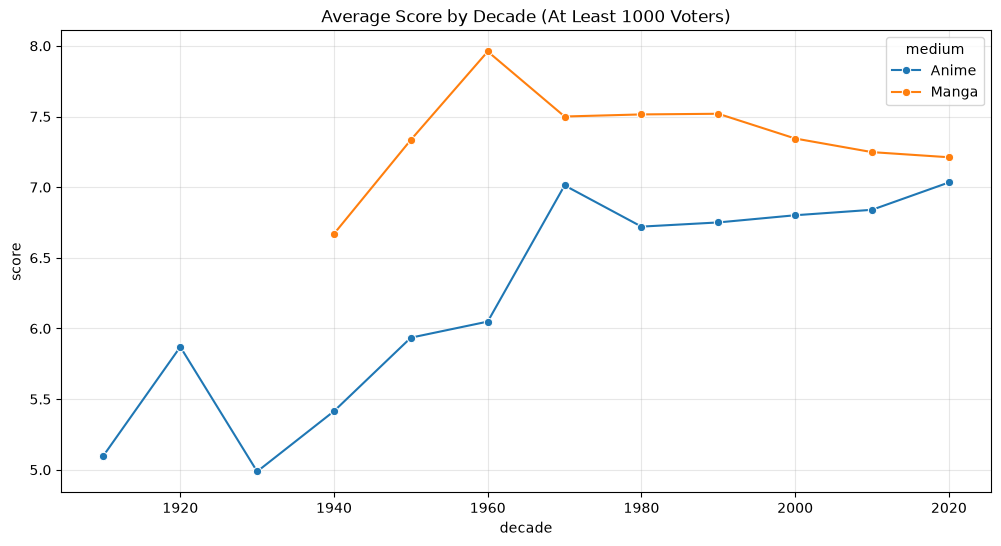

In [80]:
reliable_scores = time_dataframe[
    time_dataframe["scored_by"] >= 1000
]

decade_reliable_scores = (
    reliable_scores.groupby(["decade", "medium"])["score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=decade_reliable_scores,
    x="decade",
    y="score",
    hue="medium",
    marker="o"
)

plt.title("Average Score by Decade (At Least 1000 Voters)")
plt.grid(alpha=0.3)
plt.show()

In [81]:
decade_sample_sizes = (
    reliable_scores.groupby(["decade", "medium"])["score"]
    .count()
    .unstack()
)

print(decade_sample_sizes)

medium   Anime   Manga
decade                
1910       2.0     NaN
1920       1.0     NaN
1930       5.0     NaN
1940       2.0     1.0
1950       2.0     2.0
1960      38.0     6.0
1970      74.0    37.0
1980     359.0    76.0
1990     765.0   364.0
2000    2370.0  2335.0
2010    4436.0  3138.0
2020    1295.0   448.0


In [82]:
valid_decades = decade_sample_sizes[
    (decade_sample_sizes["Anime"] >= 100) &
    (decade_sample_sizes["Manga"] >= 100)
].index

print(valid_decades.tolist())

[1990, 2000, 2010, 2020]


In [83]:
decade_comparison = decade_reliable_scores[
    decade_reliable_scores["decade"].isin(valid_decades)
]

print(decade_comparison)

    decade medium     score
13    1990  Anime  6.750444
14    1990  Manga  7.519368
15    2000  Anime  6.801245
16    2000  Manga  7.344278
17    2010  Anime  6.839824
18    2010  Manga  7.247916
19    2020  Anime  7.033421
20    2020  Manga  7.211629


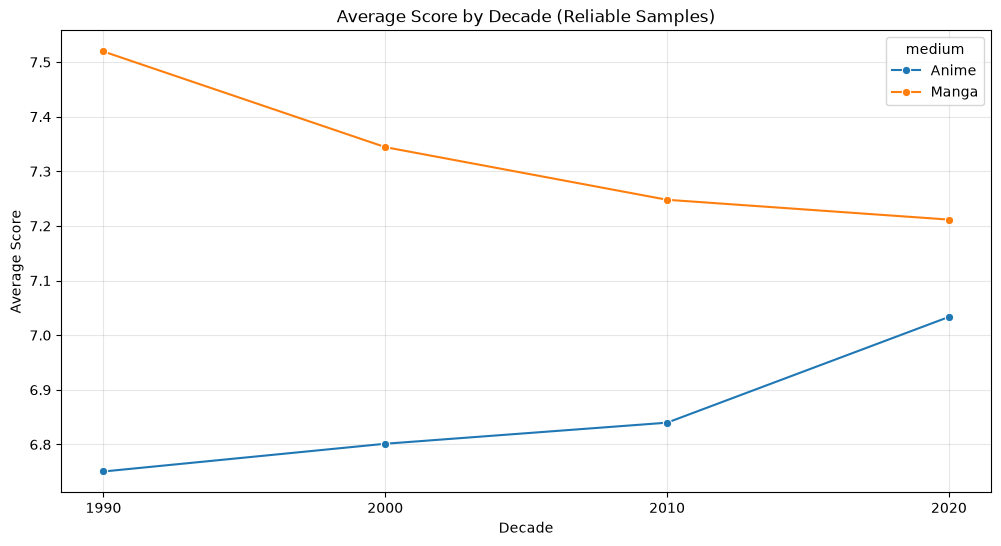

In [84]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=decade_comparison,
    x="decade",
    y="score",
    hue="medium",
    marker="o"
)

plt.title("Average Score by Decade (Reliable Samples)")
plt.xlabel("Decade")
plt.ylabel("Average Score")
plt.xticks(valid_decades)
plt.grid(alpha=0.3)

plt.show()

Conclusion

The analysis reveals opposite trends for anime and manga over time.

The average anime score increases from approximately 6.75 in the 1990s to 7.03 in the 2020s. In contrast, the average manga score decreases from approximately 7.52 to 7.21.

Although manga consistently receives higher average scores, the difference between anime and manga becomes smaller over time.

To improve the reliability of the comparison, we included only works with at least 1,000 users who scored them and decades with at least 100 qualifying works for each medium.

However, these results should be interpreted carefully due to survivorship bias, selection bias, differences in sample sizes, and the incomplete 2020s decade.

Overall, newer anime tend to receive higher scores, while older manga tend to receive higher scores within the selected dataset.

### Problem 7. Genres
Turn genres into something tidy and visualize them. You'll need at least one or two additional datasets for this.

**A quick sanity check:** Do the genres for _the same title_ of manga and anime match completely? Why?

Show which genres dominate, which ones are niche, and whether the most common genres are also the most successful by whatever measure you think is reasonable. Be careful: _common_, _beloved_, and _highly rated_ are not the same thing.

Compare genres across both types of media. Can you explain similarities and differences? Try to take into account the `source` column in the `animes.csv` dataset.

In [85]:
anime_genres_dataframe = pd.read_csv(
    "processed_data/anime_genres.csv"
)

manga_genres_dataframe = pd.read_csv(
    "processed_data/manga_genres.csv"
)

print("Anime genres shape:", anime_genres_dataframe.shape)
print("Manga genres shape:", manga_genres_dataframe.shape)

print("\nAnime genres:")
print(anime_genres_dataframe.head(10))

print("\nManga genres:")
print(manga_genres_dataframe.head(10))

Anime genres shape: (38474, 2)
Manga genres shape: (121442, 2)

Anime genres:
   anime_id     genres
0      5114     Action
1      5114  Adventure
2      5114      Drama
3      5114    Fantasy
4     11061     Action
5     11061  Adventure
6     11061    Fantasy
7     38524     Action
8     38524      Drama
9      9253      Drama

Manga genres:
   manga_id         genres
0         2         Action
1         2      Adventure
2         2  Award Winning
3         2          Drama
4         2        Fantasy
5         2         Horror
6         2   Supernatural
7        13         Action
8        13      Adventure
9        13        Fantasy


In [86]:
anime_genre_sets = (
    anime_genres_dataframe
    .groupby("anime_id")["genres"]
    .agg(set)
    .reset_index()
)

manga_genre_sets = (
    manga_genres_dataframe
    .groupby("manga_id")["genres"]
    .agg(set)
    .reset_index()
)

print(anime_genre_sets.head())
print(manga_genre_sets.head())

   anime_id                                  genres
0         1         {Action, Award Winning, Sci-Fi}
1         5                        {Action, Sci-Fi}
2         6             {Action, Sci-Fi, Adventure}
3         7  {Action, Supernatural, Drama, Mystery}
4         8      {Supernatural, Fantasy, Adventure}
   manga_id                                             genres
0         1                    {Award Winning, Drama, Mystery}
1         2  {Action, Adventure, Supernatural, Fantasy, Hor...
2         3            {Award Winning, Sci-Fi, Drama, Mystery}
3         4      {Award Winning, Sci-Fi, Drama, Slice of Life}
4         7                            {Award Winning, Sports}


In [87]:
anime_genre_sets = anime_genre_sets.merge(
    anime_dataframe[["anime_id", "normalized_title"]],
    on="anime_id",
    how="inner"
)

manga_genre_sets = manga_genre_sets.merge(
    manga_dataframe[["manga_id", "normalized_title"]],
    on="manga_id",
    how="inner"
)

print(anime_genre_sets.head())
print(manga_genre_sets.head())

   anime_id                                  genres  \
0         1         {Action, Award Winning, Sci-Fi}   
1         5                        {Action, Sci-Fi}   
2         6             {Action, Sci-Fi, Adventure}   
3         7  {Action, Supernatural, Drama, Mystery}   
4         8      {Supernatural, Fantasy, Adventure}   

                  normalized_title  
0                     cowboy bebop  
1  cowboy bebop: tengoku no tobira  
2                           trigun  
3               witch hunter robin  
4                   bouken ou beet  
   manga_id                                             genres  \
0         1                    {Award Winning, Drama, Mystery}   
1         2  {Action, Adventure, Supernatural, Fantasy, Hor...   
2         3            {Award Winning, Sci-Fi, Drama, Mystery}   
3         4      {Award Winning, Sci-Fi, Drama, Slice of Life}   
4         7                            {Award Winning, Sports}   

          normalized_title  
0                  mo

In [88]:
matching_titles = anime_genre_sets.merge(
    manga_genre_sets,
    on="normalized_title",
    how="inner",
    suffixes=("_anime", "_manga")
)

print("Matching pairs:", len(matching_titles))
print("Unique matching titles:", matching_titles["normalized_title"].nunique())

display(matching_titles.head(10))


Matching pairs: 3678
Unique matching titles: 3027


,anime_id,genres_anime,normalized_title,manga_id,genres_manga
0,1,"{Action, Award Winning, Sci-Fi}",cowboy bebop,173,"{Action, Sci-Fi, Adventure}"
1,6,"{Action, Sci-Fi, Adventure}",trigun,703,"{Action, Adventure, Comedy, Sci-Fi, Drama}"
2,15,{Sports},eyeshield 21,43,{Sports}
3,15,{Sports},eyeshield 21,93595,{Sports}
4,16,"{Romance, Comedy, Drama}",hachimitsu to clover,1009,"{Romance, Comedy, Slice of Life, Award Winning..."
5,19,"{Suspense, Drama, Mystery}",monster,1,"{Award Winning, Drama, Mystery}"
6,20,"{Action, Fantasy, Adventure}",naruto,11,"{Action, Fantasy, Adventure}"
7,20,"{Action, Fantasy, Adventure}",naruto,6444,{Action}
8,21,"{Action, Fantasy, Adventure}",one piece,13,"{Action, Fantasy, Adventure}"
9,22,{Sports},tennis no oujisama,49,{Sports}


In [89]:
matching_titles["genres_match"] = (
    matching_titles["genres_anime"] ==
    matching_titles["genres_manga"]
)

print(matching_titles["genres_match"].value_counts())

genres_match
False    2209
True     1469
Name: count, dtype: int64


In [90]:
print(
    matching_titles["genres_match"]
    .value_counts(normalize=True) * 100
)

genres_match
False    60.059815
True     39.940185
Name: proportion, dtype: float64


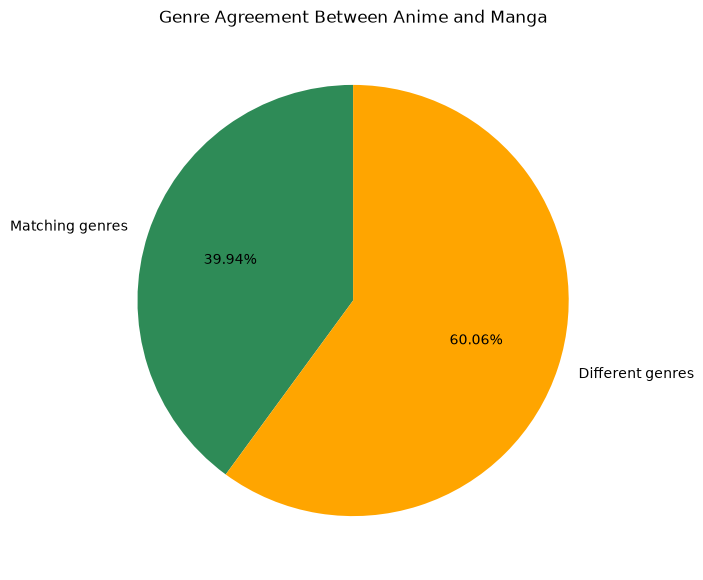

In [91]:
genre_match_counts = matching_titles["genres_match"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    [
        genre_match_counts[True],
        genre_match_counts[False]
    ],
    labels=["Matching genres", "Different genres"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["seagreen", "orange"]
)

plt.title("Genre Agreement Between Anime and Manga")

plt.show()

In [92]:
anime_genre_counts = (
    anime_genres_dataframe
    .groupby("genres")["anime_id"]
    .nunique()
    .sort_values(ascending=False)
)

manga_genre_counts = (
    manga_genres_dataframe
    .groupby("genres")["manga_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Anime genres:")
print(anime_genre_counts)

print("\nManga genres:")
print(manga_genre_counts)

Anime genres:
genres
Comedy           7154
Fantasy          5326
Action           4744
Adventure        3841
Sci-Fi           3108
Drama            2839
Romance          2065
Slice of Life    1701
Supernatural     1489
Hentai           1486
Mystery           846
Avant Garde       809
Ecchi             790
Sports            766
Horror            535
Suspense          247
Award Winning     240
Boys Love         168
Gourmet           149
Girls Love        113
Erotica            58
Name: anime_id, dtype: int64

Manga genres:
genres
Romance          16876
Comedy           14099
Hentai           11208
Fantasy          10952
Boys Love         9610
Drama             9303
Action            8910
Erotica           8844
Supernatural      7471
Slice of Life     5155
Adventure         3912
Ecchi             3569
Sci-Fi            3231
Mystery           2441
Horror            1699
Girls Love        1608
Sports            1116
Suspense           519
Award Winning      439
Gourmet            410
Avant 

In [93]:
anime_genre_counts = (
    anime_genres_dataframe
    .groupby("genres")["anime_id"]
    .nunique()
    .sort_values(ascending=False)
)

manga_genre_counts = (
    manga_genres_dataframe
    .groupby("genres")["manga_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Anime genres:")
print(anime_genre_counts)

print("\nManga genres:")
print(manga_genre_counts)

Anime genres:
genres
Comedy           7154
Fantasy          5326
Action           4744
Adventure        3841
Sci-Fi           3108
Drama            2839
Romance          2065
Slice of Life    1701
Supernatural     1489
Hentai           1486
Mystery           846
Avant Garde       809
Ecchi             790
Sports            766
Horror            535
Suspense          247
Award Winning     240
Boys Love         168
Gourmet           149
Girls Love        113
Erotica            58
Name: anime_id, dtype: int64

Manga genres:
genres
Romance          16876
Comedy           14099
Hentai           11208
Fantasy          10952
Boys Love         9610
Drama             9303
Action            8910
Erotica           8844
Supernatural      7471
Slice of Life     5155
Adventure         3912
Ecchi             3569
Sci-Fi            3231
Mystery           2441
Horror            1699
Girls Love        1608
Sports            1116
Suspense           519
Award Winning      439
Gourmet            410
Avant 

In [94]:
anime_genre_percentage = (
    anime_genre_counts /
    anime_dataframe["anime_id"].nunique() * 100
)

manga_genre_percentage = (
    manga_genre_counts /
    manga_dataframe["manga_id"].nunique() * 100
)

genre_comparison = pd.DataFrame({
    "anime_count": anime_genre_counts,
    "manga_count": manga_genre_counts,
    "anime_percentage": anime_genre_percentage,
    "manga_percentage": manga_genre_percentage
})

display(genre_comparison.round(2))

,anime_count,manga_count,anime_percentage,manga_percentage
genres,,,,
Action,4744,8910,18.99,13.74
Adventure,3841,3912,15.37,6.03
Avant Garde,809,70,3.24,0.11
Award Winning,240,439,0.96,0.68
Boys Love,168,9610,0.67,14.82
Comedy,7154,14099,28.63,21.75
Drama,2839,9303,11.36,14.35
Ecchi,790,3569,3.16,5.50
Erotica,58,8844,0.23,13.64


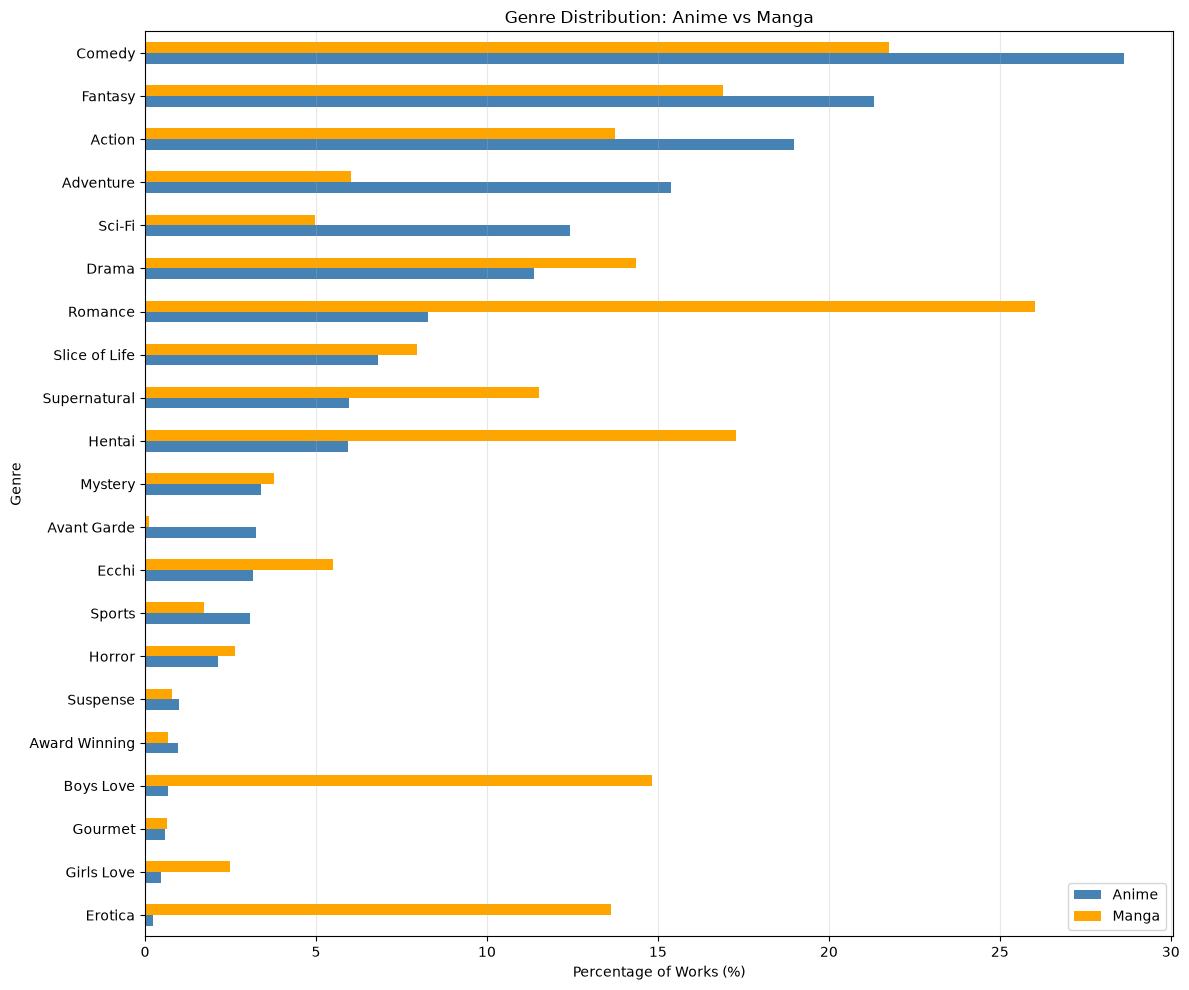

In [95]:
genre_comparison_sorted = genre_comparison.sort_values(
    "anime_percentage",
    ascending=True
)

genre_comparison_sorted[
    ["anime_percentage", "manga_percentage"]
].plot(
    kind="barh",
    figsize=(12, 10),
    color=["steelblue", "orange"]
)

plt.title("Genre Distribution: Anime vs Manga")
plt.xlabel("Percentage of Works (%)")
plt.ylabel("Genre")
plt.legend(["Anime", "Manga"])
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [96]:
anime_niche_genres = genre_comparison[
    genre_comparison["anime_percentage"] < 1
][["anime_count", "anime_percentage"]].sort_values(
    "anime_percentage"
)

manga_niche_genres = genre_comparison[
    genre_comparison["manga_percentage"] < 1
][["manga_count", "manga_percentage"]].sort_values(
    "manga_percentage"
)

print("Niche Anime genres:")
display(anime_niche_genres)

print("Niche Manga genres:")
display(manga_niche_genres)

Niche Anime genres:


,anime_count,anime_percentage
genres,,
Erotica,58,0.232139
Girls Love,113,0.452271
Gourmet,149,0.596358
Boys Love,168,0.672403
Award Winning,240,0.960576
Suspense,247,0.988593


Niche Manga genres:


,manga_count,manga_percentage
genres,,
Avant Garde,70,0.107970
Gourmet,410,0.632394
Award Winning,439,0.677124
Suspense,519,0.800518


In [97]:
anime_genre_details = anime_genres_dataframe.merge(
    anime_dataframe[
        ["anime_id", "score", "scored_by", "members", "favorites"]
    ],
    on="anime_id",
    how="inner"
)

manga_genre_details = manga_genres_dataframe.merge(
    manga_dataframe[
        ["manga_id", "score", "scored_by", "members", "favorites"]
    ],
    on="manga_id",
    how="inner"
)

display(anime_genre_details.head())
display(manga_genre_details.head())

,anime_id,genres,score,scored_by,members,favorites
0,5114,Action,9.10,2037075,3206028,219036
1,5114,Adventure,9.10,2037075,3206028,219036
2,5114,Drama,9.10,2037075,3206028,219036
3,5114,Fantasy,9.10,2037075,3206028,219036
4,11061,Action,9.04,1671587,2688079,202109


,manga_id,genres,score,scored_by,members,favorites
0,2,Action,9.47,319696,643969,119470
1,2,Adventure,9.47,319696,643969,119470
2,2,Award Winning,9.47,319696,643969,119470
3,2,Drama,9.47,319696,643969,119470
4,2,Fantasy,9.47,319696,643969,119470


### * Problem 8. Themes and demographics
As a continuation of the last problem, try to explore, visualize, and come up with useful metrics for themes and demographics. A big challenge that you'll face is that a lot of these values (more than half) are actually missing. You'll have to comment on what's missing and why (in case you haven't already done so last time), if you could fill in the values somehow, and how to handle the info that you do have.

Think **very** carefully about what biases might the missing information leave in the data (e.g., smaller productions are not as well-represented because nobody cared enough to fill the information in the site).

In [ ]:
anime_themes = pd.read_csv("processed_data/anime_themes.csv")
manga_themes = pd.read_csv("processed_data/manga_themes.csv")

anime_demographics = pd.read_csv("processed_data/anime_demographics.csv")
manga_demographics = pd.read_csv("processed_data/manga_demographics.csv")

display(anime_themes.head())
display(manga_themes.head())
display(anime_demographics.head())
display(manga_demographics.head())

,anime_id,themes
0,5114,Military
1,38524,Gore
2,38524,Military
3,38524,Survival
4,9253,Psychological


,manga_id,themes
0,2,Gore
1,2,Military
2,2,Mythology
3,2,Psychological
4,1706,Historical


,anime_id,demographics
0,5114,Shounen
1,11061,Shounen
2,38524,Shounen
3,28851,Shounen
4,40028,Shounen


,manga_id,demographics
0,2,Seinen
1,13,Shounen
2,1706,Seinen
3,1706,Shounen
4,4632,Seinen


### Problem 9. The production side
Choose one production-side feature - studios, producers, publishers, authors, serializations, or something similar - and visualize it. Optionally, you could explore all features.

Try to make the plot reveal something about the structure: who appears often and why? Once again (as we asked before), how do we measure how "popular" or "beloved" something is?

In [ ]:
import os

print(os.listdir("processed_data"))
print(anime_dataframe.columns.tolist())

['anime_cleaned.csv', 'anime_demographics.csv', 'anime_genres.csv', 'anime_themes.csv', 'manga_cleaned.csv', 'manga_demographics.csv', 'manga_genres.csv', 'manga_themes.csv', 'unified_works.csv']
['anime_id', 'title', 'type', 'score', 'scored_by', 'status', 'episodes', 'start_date', 'end_date', 'source', 'members', 'favorites', 'episode_duration', 'total_duration', 'rating', 'sfw', 'approved', 'created_at', 'updated_at', 'start_year', 'start_season', 'real_start_date', 'real_end_date', 'genres', 'themes', 'demographics', 'studios', 'producers', 'licensors', 'synopsis', 'display_title', 'title_japanese', 'title_synonyms', 'episode_duration_minutes', 'total_duration_minutes', 'genres_count', 'themes_count', 'demographics_count', 'normalized_title', 'weighted_score']


### * Problem 10. Scores by production
Revisit your analysis in the previous problems where you explored scores and popularity. Now compare with studios / producers. 

Are there universally liked studios? Are there some which only make one very niche thing, a cult classic? How does production (and reception) compare across the two types of work? Document your findings.

In [ ]:
print(manga_dataframe.columns.tolist())

['manga_id', 'title', 'type', 'score', 'scored_by', 'status', 'volumes', 'chapters', 'start_date', 'end_date', 'members', 'favorites', 'sfw', 'approved', 'created_at_before', 'updated_at', 'real_start_date', 'real_end_date', 'genres', 'themes', 'demographics', 'authors', 'serializations', 'synopsis', 'display_title', 'title_japanese', 'title_synonyms', 'start_year', 'genres_count', 'themes_count', 'demographics_count', 'normalized_title', 'weighted_score']


In [130]:
manga_production["authors"] = manga_production["authors"].apply(
    lambda x: f"{x['first_name']} {x['last_name']}".strip()
    if isinstance(x, dict) else x
)

manga_production = manga_production.drop_duplicates(
    subset=["manga_id", "authors"]
)

display(manga_production.head())

,manga_id,title,authors,score,scored_by,members,favorites
0,2,Berserk,Kentarou Miura,9.47,319696,643969,119470
0,2,Berserk,Studio Gaga,9.47,319696,643969,119470
1,13,One Piece,Eiichiro Oda,9.22,355375,579557,111462
2,1706,JoJo no Kimyou na Bouken Part 7: Steel Ball Run,Hirohiko Araki,9.30,151433,248511,41713
3,4632,Oyasumi Punpun,Inio Asano,9.02,168459,413897,49361


In [131]:
for data, column, id_column in [
    (anime_production, "studios", "anime_id"),
    (manga_production, "authors", "manga_id")
]:
    statistics = (
        data[data["scored_by"] >= 1000]
        .groupby(column)
        .agg(
            work_count=(id_column, "nunique"),
            average_score=("score", "mean"),
            score_std=("score", "std"),
            average_members=("members", "mean")
        )
    )

    statistics = statistics[statistics["work_count"] >= 10]

    print(column.upper())

    display(
        statistics.sort_values("average_score", ascending=False)
        .head(10).round(2)
    )

STUDIOS


,work_count,average_score,score_std,average_members
studios,,,,
Shuka,18,7.71,0.77,155682.33
Motion Magic,10,7.68,0.24,6388.50
Animation Do,10,7.63,0.15,174538.50
Bandai Namco Pictures,39,7.51,0.81,81957.95
TROYCA,15,7.48,0.62,158182.27
Wit Studio,60,7.45,0.80,395635.72
Kitty Film Mitaka Studio,10,7.42,0.75,43972.10
B.CMAY PICTURES,13,7.41,0.83,74111.92
MAPPA,66,7.40,0.84,347465.06


AUTHORS


,work_count,average_score,score_std,average_members
authors,,,,
Ryukishi07,23,8.03,0.49,12128.65
Naoki Urasawa,10,8.00,0.87,75619.50
Nobuyuki Fukumoto,14,7.99,0.39,9224.07
Ryohgo Narita,11,7.85,0.57,11252.00
ISIN NISIO,23,7.73,0.87,15860.00
Asumiko Nakamura,17,7.69,0.48,8180.18
Mei Sakuraga,16,7.69,0.29,5366.25
Isaku Natsume,12,7.68,0.24,6757.33
Osamu Tezuka,16,7.68,0.61,16056.81


In [132]:
for data, column, id_column in [
    (anime_production, "studios", "anime_id"),
    (manga_production, "authors", "manga_id")
]:
    statistics = (
        data[data["scored_by"] >= 1000]
        .groupby(column)
        .agg(
            work_count=(id_column, "nunique"),
            average_score=("score", "mean"),
            score_std=("score", "std"),
            average_members=("members", "mean")
        )
    )

    statistics = statistics[statistics["work_count"] >= 10]

    statistics = statistics.sort_values("average_score", ascending=False)

    print(column.upper())
    display(statistics.head(10).round(2))

STUDIOS


,work_count,average_score,score_std,average_members
studios,,,,
Shuka,18,7.71,0.77,155682.33
Motion Magic,10,7.68,0.24,6388.50
Animation Do,10,7.63,0.15,174538.50
Bandai Namco Pictures,39,7.51,0.81,81957.95
TROYCA,15,7.48,0.62,158182.27
Wit Studio,60,7.45,0.80,395635.72
Kitty Film Mitaka Studio,10,7.42,0.75,43972.10
B.CMAY PICTURES,13,7.41,0.83,74111.92
MAPPA,66,7.40,0.84,347465.06


AUTHORS


,work_count,average_score,score_std,average_members
authors,,,,
Ryukishi07,23,8.03,0.49,12128.65
Naoki Urasawa,10,8.00,0.87,75619.50
Nobuyuki Fukumoto,14,7.99,0.39,9224.07
Ryohgo Narita,11,7.85,0.57,11252.00
ISIN NISIO,23,7.73,0.87,15860.00
Asumiko Nakamura,17,7.69,0.48,8180.18
Mei Sakuraga,16,7.69,0.29,5366.25
Isaku Natsume,12,7.68,0.24,6757.33
Osamu Tezuka,16,7.68,0.61,16056.81


In [133]:
for data, column, id_column in [
    (anime_production, "studios", "anime_id"),
    (manga_production, "authors", "manga_id")
]:
    work_counts = data.groupby(column)[id_column].nunique()

    single_work = work_counts[work_counts == 1].index

    cult_classics = data[
        (data[column].isin(single_work)) &
        (data["score"] >= 8) &
        (data["scored_by"] >= 100) &
        (data["members"] < 10000)
    ]

    print(column.upper())

    display(
        cult_classics.sort_values("score", ascending=False)
        .head(10)
    )

STUDIOS


,anime_id,title,studios,score,scored_by,members,favorites
2376,4921,Ramayana: The Legend of Prince Rama,Nippon Ramayana Film Co.,8.33,4941,9670,173


AUTHORS


,manga_id,title,authors,score,scored_by,members,favorites
3669,102875,Fata Morgana no Yakata: Anata no Genten ni Ita...,Moyataro,8.64,595,2264,324
830,140765,Tian Guan Ci Fu,STARember,8.60,2858,8662,683
1207,6978,Ginga Eiyuu Densetsu,Naoyuki Katou,8.59,1977,9411,281
1207,6978,Ginga Eiyuu Densetsu,Yukihisa Kamoshita,8.59,1977,9411,281
1100,98380,Bungou Stray Dogs,Hiro Iwahata,8.43,2242,9876,1348
934,145539,Seasons of Blossom,NEMONE,8.36,2683,6629,380
934,145539,Seasons of Blossom,Hongduck,8.36,2683,6629,380
768,107539,Life: Senjou no Bokura,Miya Tokokura,8.34,3237,5764,237
2307,138424,Watashi no Oshi wa Akuyaku Reijou.: Revolution,Hanagata,8.27,1046,3104,204
1310,149493,Daytime Star,Chae-eun,8.26,1963,4179,124


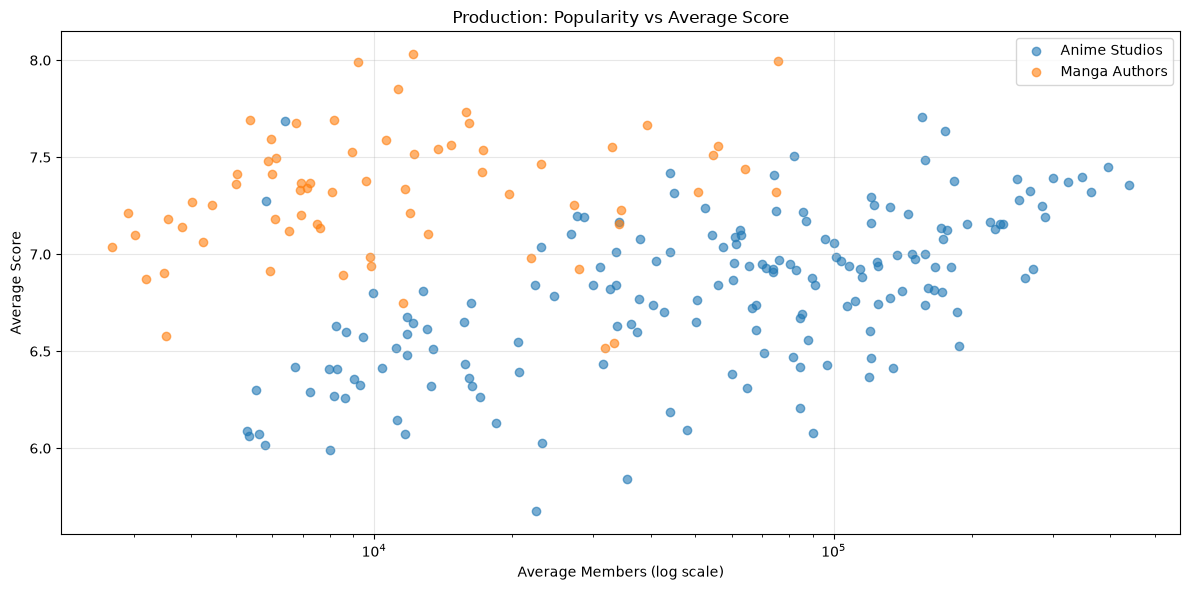

In [134]:
fig, ax = plt.subplots(figsize=(12, 6))

for data, column, id_column, label in [
    (anime_production, "studios", "anime_id", "Anime Studios"),
    (manga_production, "authors", "manga_id", "Manga Authors")
]:
    stats = (
        data[data["scored_by"] >= 1000]
        .groupby(column)
        .agg(
            work_count=(id_column, "nunique"),
            average_score=("score", "mean"),
            average_members=("members", "mean")
        )
    )

    stats = stats[stats["work_count"] >= 10]

    ax.scatter(
        stats["average_members"],
        stats["average_score"],
        label=label,
        alpha=0.6
    )

ax.set_xscale("log")
ax.set_xlabel("Average Members (log scale)")
ax.set_ylabel("Average Score")
ax.set_title("Production: Popularity vs Average Score")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusion

Shuka and Ryukishi07 have the highest average scores among the selected anime studios and manga authors. Animation Do and Nobuyuki Fukumoto demonstrate consistently high ratings with relatively low standard deviations.

Potential cult classics, such as Ramayana: The Legend of Prince Rama and Fata Morgana no Yakata, show that highly rated works can have relatively small audiences.

Anime studios generally attract larger audiences, while manga authors tend to receive higher average scores in the selected sample.

Overall, productivity, popularity and audience ratings represent different measures of success. The results depend on the selected thresholds, and high ratings alone do not prove cult status.

### * Problem 12. Making a better plot
Try to take one plot - I'm almost convinced this will be from Problem 11. Iterate over it to make it look better: show more info in one image but donb't overwhelm the reader, make it easier to read and understand. Use `matplotlib` but try to push it to the limit of what it can do.

I suggest that you keep your plot non-animated and non-interactive for simplicity. Ideally, show all intermediate actions, results, and how you decided to improve the plot.

### * Problem 13. Continue cleaning and exploring
Perform what other cleaning operations / transformations / EDA you might see fit. Save the final results as one or more tables. Try using **dvc** to keep track of versions and what you did to them; and to possibly be able to revert if something goes wrong.

You can do as little, or as much as you'd like. Have fun! :)